In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from matplotlib import pyplot as plt

# AJOUTS pour l'imputation KNN, les pipelines et la comparaison
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

data = pd.read_csv("C:/Users/Administrateur/Desktop/Predection_IDS_Attaque/X-IIoTID dataset.csv")
print(f"Shape : {data.shape}")
print(f"\nColonnes :\n{data.columns.tolist()}")

Shape : (820834, 68)

Colonnes :
['Date', 'Timestamp', 'Scr_IP', 'Scr_port', 'Des_IP', 'Des_port', 'Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Conn_state', 'missed_bytes', 'is_syn_only', 'Is_SYN_ACK', 'is_pure_ack', 'is_with_payload', 'FIN or RST', 'Bad_checksum', 'is_SYN_with_RST', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'anomaly_alert', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate', 'Scr_packts_ratio', 'Des_pkts_ratio', 'Scr_bytes_ratio', 'Des_bytes_ratio', 'Avg_user_time', 'Std_user_time', 'Avg_nice_time', 'Std_nice_time', 'Avg_system_time', 'Std_system_time', 'Avg_iowait_time', 'Std_iowait_time', 'Avg_ideal_time', 'Std_ideal_time', 'Avg_tps', 'Std_tps', 'Avg_rtps', 'Std_rtps', 'Avg_wtps', 'Std_wtps', 'Avg_ldavg_1', 'Std_ldavg_1', 'Avg_kbmemused', 'Std_kbmemused', 'Avg_num_Proc/s', 'Std_num_proc/s', 'Avg_num_cswch/s', 'std_num_cswch/s', 'OSSEC_alert', 'OSSEC_alert_level', 'Login_attempt', 'Succesful_login', 'File_activity', 'Process_activ

In [2]:
# Afficher toutes les colonnes (pandas en cache une partie par défaut)
pd.set_option("display.max_columns", None)
data.head(8)

,Date,Timestamp,Scr_IP,Scr_port,Des_IP,Des_port,Protocol,Service,Duration,Scr_bytes,Des_bytes,Conn_state,missed_bytes,is_syn_only,Is_SYN_ACK,is_pure_ack,is_with_payload,FIN or RST,Bad_checksum,is_SYN_with_RST,Scr_pkts,Scr_ip_bytes,Des_pkts,Des_ip_bytes,anomaly_alert,total_bytes,total_packet,paket_rate,byte_rate,Scr_packts_ratio,Des_pkts_ratio,Scr_bytes_ratio,Des_bytes_ratio,Avg_user_time,Std_user_time,Avg_nice_time,Std_nice_time,Avg_system_time,Std_system_time,Avg_iowait_time,Std_iowait_time,Avg_ideal_time,Std_ideal_time,Avg_tps,Std_tps,Avg_rtps,Std_rtps,Avg_wtps,Std_wtps,Avg_ldavg_1,Std_ldavg_1,Avg_kbmemused,Std_kbmemused,Avg_num_Proc/s,Std_num_proc/s,Avg_num_cswch/s,std_num_cswch/s,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,class1,class2,class3
0,9/01/2020,1578540956,192.168.2.199,49278,192.168.2.10,80,tcp,http,0.67369,13437,34924,1,0,True,True,True,True,True,False,False,105,18905,105,40392,TRUE,107658,210,311.7160712,159803.4704,0.5,0.5,0.300414275,0.699585725,9.207,5.55584206,10.994,1.356305275,4.864,1.873004004,0.311,0.224653066,74.624,8.245611196,12.297,10.38585004,8,10.50714043,4.297,2.723578712,2.146,0.102781321,915852.8,2507.97563,5.1,3.238826948,2806.2,158.7493622,1,5,0,0,0,0,0,0,Scanning_vulnerability,Reconnaissance,Attack
1,13/01/2020,1578871873,10.0.1.5,39769,131.236.3.92,53,udp,dns,0.000083,78,0,1,0,False,False,False,True,False,False,False,2,134,0,0,FALSE,212,2,24096.38554,2554216.867,1,0,1,0,12.326,6.674247823,2.895,1.604302029,3.778,2.099741889,2.741,5.327471164,78.263,8.869399134,6.6,5.713142743,0,0,6.6,5.713142743,0.612,0.037629775,910498.4,4044.112046,1,0.894427191,1561.6,247.0802299,0,0,0,0,0,0,0,0,Normal,Normal,Normal
2,9/01/2020,1578522486,172.24.1.80,59050,172.24.1.1,53,udp,dns,0.000132,38,38,1,0,False,False,False,True,False,False,False,1,66,1,66,FALSE,208,2,15151.51515,1575757.576,0.5,0.5,0.5,0.5,6.931,6.416007248,0.706,0.408905857,1.693,0.771635277,2.423,3.829809525,88.245,7.112108337,37.4,40.19004852,30.1,39.79811553,7.3,3.1,0.55,0.02,921020.4,2139.652645,1,0,1603.3,294.1390997,0,0,0,0,0,0,0,0,Normal,Normal,Normal
3,27/02/2020,1582757640,192.168.2.196,37966,192.168.2.10,1880,tcp,websocket,9.378481,1121,484,1,0,True,True,True,True,True,False,False,8,1545,6,804,FALSE,3954,14,1.492779055,421.6034558,0.571428571,0.428571429,0.67425392,0.32574608,10.244,7.932040343,1.965,1.514168088,3.941,1.709055002,0.509,0.425522032,83.339,10.20608686,29,26.57442379,23.3,26.12680616,5.7,6.229767251,0.708,0.026,915874.8,977.8851466,7.2,5.325410782,1685.3,467.8737116,0,0,1,1,1,1,1,1,Normal,Normal,Normal
4,16/12/2019,1576452612,172.24.1.80,38233,172.24.1.1,53,udp,dns,0.000074,-,-,1,0,False,False,False,True,False,False,False,-,-,-,-,FALSE,-,-,-,-,-,-,-,-,5.181,5.980458929,2.365,1.284462923,2.415,1.401151312,1.803,4.478256469,88.239,8.090017862,9.8,1.326649916,0.1,0.3,9.7,1.268857754,0.536,0.030066593,918213.2,2342.93836,0.6,0.489897949,1456.5,346.8847791,0,0,0,0,0,0,0,0,Normal,Normal,Normal
5,31/01/2020,1580452611,192.168.10.155,50502,192.168.2.10,80,tcp,http,5.153928,460,671,1,0,True,True,True,True,True,False,False,12,1560,10,1878,FALSE,4569,22,4.268588929,886.5083098,0.545454545,0.454545455,0.442109871,0.557890129,10.579,6.866914081,3.273,2.366140528,2.638,1.040920746,0.279,0.210829315,83.233,9.57921192,19.3,18.42308335,8.8,10.20588066,10.5,13.52959719,0.524,0.028,910370.8,4006.8817,0.9,0.538516481,1366.9,304.0626416,0,0,0,0,0,0,1,0,Normal,Normal,Normal
6,12/12/2019,1576100087,172.24.1.80,39649,172.24.1.1,53,udp,dns,0.000119,37,37,1,0,False,False,False,True,False,False,False,1,65,1,65,FALSE,204,2,16806.72269,1714285.714,0.5,0.5,0.5,0.5,2.47,4.589873637,2.292,1.712418173,2.552,0.949187021,0.504,1.098446175,92.183,5.98835712,10.3,7.523961722,5.1,6.425729531,5.2,5.035871325,0.44,0.02,907108,2995.482465,1,0,1185.5,188.0756497,0,0,0,0,0,0,0,0,Normal,Normal,Normal
7,21/02/2020,1582241330,172.24.1.34,52195,172.24.1.1,53,udp,dns,0.000184,36,3

In [3]:
# Dans ce dataset, "-" signifie "pas de valeur". Je le remplace par NaN
# pour que pandas le reconnaisse comme valeur manquante.
data = data.replace("-", np.nan)

In [4]:
data.info()

# Nombre de valeurs manquantes par colonne 
manquantes = data.isnull().sum()
pourcentage = (data.isnull().mean() * 100).round(2)

# Je regroupe les deux résultats dans un seul tableau
resume = pd.DataFrame({
    "Nb manquantes": manquantes,
    "Pourcentage (%)": pourcentage
})

# Je garde uniquement les colonnes qui ont des valeurs manquantes, triées de la plus touchée à la moins touchée
resume = resume[resume["Nb manquantes"] > 0].sort_values("Nb manquantes", ascending=False)

print("_______Les colonnes avec des valeurs manquantes_______")
print(resume)
print("\nNombre de colonnes concernées :", len(resume), "sur", data.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 820834 entries, 0 to 820833
Data columns (total 68 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Date                         820503 non-null  str  
 1   Timestamp                    820537 non-null  str  
 2   Scr_IP                       820834 non-null  str  
 3   Scr_port                     820834 non-null  str  
 4   Des_IP                       820834 non-null  str  
 5   Des_port                     820834 non-null  str  
 6   Protocol                     820834 non-null  str  
 7   Service                      820834 non-null  str  
 8   Duration                     745073 non-null  str  
 9   Scr_bytes                    596963 non-null  str  
 10  Des_bytes                    596963 non-null  str  
 11  Conn_state                   820834 non-null  int64
 12  missed_bytes                 820680 non-null  str  
 13  is_syn_only                  820834 non-

In [5]:
# Colonnes qui restent en catégories ou identifiants
cols_texte = ["Scr_IP", "Des_IP", "Scr_port", "Des_port", "Protocol", "Service",
              "anomaly_alert", "class1", "class2", "class3", "Date", "Timestamp"]

# Je convertis en nombres les colonnes encore en texte (les valeurs invalides deviennent NaN)
for c in data.columns:
    if c not in cols_texte and not pd.api.types.is_numeric_dtype(data[c]):
        data[c] = pd.to_numeric(data[c], errors="coerce")

# Les trois groupes de colonnes qui manquent ensemble
grp_A = ["Scr_bytes", "Des_bytes", "total_bytes", "paket_rate", "byte_rate",
         "Scr_bytes_ratio", "Des_bytes_ratio"]
grp_B = ["Scr_pkts", "Des_pkts", "Scr_ip_bytes", "Des_ip_bytes",
         "total_packet", "Scr_packts_ratio", "Des_pkts_ratio"]
grp_C = ["Duration"]

# Indicateur par groupe : True si au moins une valeur du groupe manque sur la ligne
ind = pd.DataFrame({
    "A_octets":  data[grp_A].isnull().any(axis=1),
    "B_paquets": data[grp_B].isnull().any(axis=1),
    "C_duration": data[grp_C].isnull().any(axis=1),
})
print(ind.mean().round(4) * 100)   # pourcentage de lignes touchées par groupe

A_octets      27.27
B_paquets     18.61
C_duration     9.23
dtype: float64


In [6]:
# Pourcentage de manquants par colonne (recalculé APRÈS la conversion des types)
pourcentage = data.isnull().mean() * 100

# Règle :  < 5 % -> supprimer les lignes | > 50 % -> supprimer la colonne | entre les deux -> imputer
cols_moins_5 = pourcentage[(pourcentage > 0) & (pourcentage < 5)].index.tolist()
cols_plus_50 = pourcentage[pourcentage > 50].index.tolist()
cols_a_imputer = pourcentage[(pourcentage >= 5) & (pourcentage <= 50)].index.tolist()

print("Colonnes < 5 % (suppression des lignes) :", cols_moins_5)
print("Colonnes > 50 % (suppression de la colonne) :", cols_plus_50)
print("Colonnes entre 5 % et 50 % (imputation KNN / médiane) :", cols_a_imputer)

avant = len(data)
data = data.drop(columns=cols_plus_50)                       # liste normalement vide ici
data = data.dropna(subset=cols_moins_5).reset_index(drop=True)
print("Lignes supprimées :", avant - len(data))

Colonnes < 5 % (suppression des lignes) : ['Date', 'Timestamp', 'missed_bytes', 'anomaly_alert', 'Avg_user_time', 'Std_user_time', 'Avg_nice_time', 'Std_nice_time', 'Avg_system_time', 'Std_system_time', 'Avg_iowait_time', 'Std_iowait_time', 'Avg_ideal_time', 'Std_ideal_time', 'Avg_tps', 'Std_tps', 'Avg_rtps', 'Std_rtps', 'Avg_wtps', 'Std_wtps', 'Avg_ldavg_1', 'Std_ldavg_1', 'Avg_kbmemused', 'Std_kbmemused', 'Avg_num_Proc/s', 'Std_num_proc/s', 'Avg_num_cswch/s', 'std_num_cswch/s']
Colonnes > 50 % (suppression de la colonne) : []
Colonnes entre 5 % et 50 % (imputation KNN / médiane) : ['Duration', 'Scr_bytes', 'Des_bytes', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate', 'Scr_packts_ratio', 'Des_pkts_ratio', 'Scr_bytes_ratio', 'Des_bytes_ratio']
Lignes supprimées : 1652


***Remarque :***
Date et Timestamp ont 0,04 % de valeurs manquantes (moins de 5 %) : je supprime ces lignes.
15 autres colonnes ont entre 9 % et 28 % de valeurs manquantes (entre 5 % et 50 %) : je les impute, avec KNN et avec la médiane, puis je compare les deux.
Aucune colonne ne dépasse 50 %.

In [7]:
# Date et Timestamp ont 0,04 % de valeurs manquantes, soit moins de 5 % : leurs lignes ont déjà
# été supprimées dans la cellule précédente. Je vérifie qu'il n'en reste plus.
# Règle : moins de 5 % = suppression des lignes ; plus de 50 % = suppression de la colonne ;
# entre les deux = imputation selon le mécanisme (MCAR : moyenne/médiane, MAR : KNN/MICE,
# MNAR : colonne indicateur).
cols = ["Date", "Timestamp"]
print(data[cols].isnull().sum())

Date         0
Timestamp    0
dtype: int64


In [8]:
# 1) Colonnes constantes (valent False sur tout le dataset)
data = data.drop(columns=["Bad_checksum", "is_SYN_with_RST"])

# 2) Doublons exacts
print("Doublons exacts :", data.duplicated().sum())
avant = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print("Lignes supprimées :", avant - len(data), "| Lignes restantes :", len(data))

# 3) Vérifier que la répartition de la cible n'a pas changé
print(data["class3"].value_counts(normalize=True).round(4))

Doublons exacts : 6219
Lignes supprimées : 6219 | Lignes restantes : 812963
class3
Normal    0.5136
Attack    0.4864
Name: proportion, dtype: float64


In [9]:
# Le dataset complet a 820 834 lignes, ce qui rend les calculs lents.
# Je travaille sur un échantillon aléatoire stratifié de 50000 lignes, pour garder
# les mêmes proportions de classes que le dataset complet.
# La cible est class3 : je stratifie donc sur class3 (et non plus sur class1).
# random_state=42 permet d'obtenir toujours le même échantillon.
print(data["class3"].value_counts())

data_small, data_unused = train_test_split(
    data,
    train_size=50000,
    stratify=data["class3"],
    random_state=42
)

data_small = data_small.reset_index(drop=True)

print("Échantillon utilisé :", data_small.shape)
print("Données non utilisées :", data_unused.shape)

print(data_small.shape)
print(data_small["class1"].value_counts())
print(data_small["class3"].value_counts())

# Je sauvegarde l'échantillon dans un fichier CSV pour pouvoir le réutiliser
# sans recharger le dataset complet.
import os

DOSSIER_RAW = "C:/Users/Administrateur/mlops-ids-attaque/data/raw"
os.makedirs(DOSSIER_RAW, exist_ok=True)

data_small.to_csv(f"{DOSSIER_RAW}/data_small_50000.csv", index=False)
print("Fichier sauvegardé :", f"{DOSSIER_RAW}/data_small_50000.csv")

class3
Normal    417513
Attack    395450
Name: count, dtype: int64
Échantillon utilisé : (50000, 66)
Données non utilisées : (762963, 66)
(50000, 66)
class1
Normal                            25678
RDOS                               8648
Scanning_vulnerability             3314
Generic_scanning                   3080
BruteForce                         2919
MQTT_cloud_broker_subscription     1419
Exfiltration                       1405
Discovering_resources              1403
insider_malcious                    901
Modbus_register_reading             350
False_data_injection                314
Dictionary                          172
C&C                                 161
TCP Relay                           119
fuzzing                              57
Reverse_shell                        51
MitM                                  9
Name: count, dtype: int64
class3
Normal    25678
Attack    24322
Name: count, dtype: int64
Fichier sauvegardé : C:/Users/Administrateur/mlops-ids-attaque/data/raw/

In [10]:
data_small.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 66 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Date                         50000 non-null  str    
 1   Timestamp                    50000 non-null  str    
 2   Scr_IP                       50000 non-null  str    
 3   Scr_port                     50000 non-null  str    
 4   Des_IP                       50000 non-null  str    
 5   Des_port                     50000 non-null  str    
 6   Protocol                     50000 non-null  str    
 7   Service                      50000 non-null  str    
 8   Duration                     45373 non-null  float64
 9   Scr_bytes                    36292 non-null  float64
 10  Des_bytes                    36292 non-null  float64
 11  Conn_state                   50000 non-null  int64  
 12  missed_bytes                 50000 non-null  float64
 13  is_syn_only                

***Remarque :***
Dans l'échantillon, `Date` et `Timestamp` sont de type texte alors que ce sont des dates : je les convertis.
Les autres colonnes numériques ont déjà été converties avant l'échantillonnage (cellule 5).

In [11]:
# Date : format jour/mois/année. Le "if" évite de convertir deux fois si je relance la cellule.
if not pd.api.types.is_datetime64_any_dtype(data_small["Date"]):
    data_small["Date"] = pd.to_datetime(data_small["Date"], dayfirst=True, errors="coerce")

# Timestamp : temps Unix en secondes (10 chiffres)
if not pd.api.types.is_datetime64_any_dtype(data_small["Timestamp"]):
    data_small["Timestamp"] = pd.to_datetime(
        pd.to_numeric(data_small["Timestamp"], errors="coerce"), unit="s", errors="coerce"
    )

# Vérification : on doit obtenir 0 et 0
print(data_small[["Date", "Timestamp"]].isnull().sum())
print(data_small[["Date", "Timestamp"]].head())

Date         0
Timestamp    0
dtype: int64
        Date           Timestamp
0 2020-02-25 2020-02-25 03:22:53
1 2020-02-24 2020-02-24 00:31:51
2 2020-01-31 2020-01-31 05:34:32
3 2020-02-22 2020-02-22 05:53:28
4 2019-12-16 2019-12-15 23:14:22


In [12]:
# J'extrais l'information temporelle utile AVANT de supprimer les colonnes d'origine.
# Je ne garde ni le mois ni l'année : les données couvrent seulement 4 mois (déc. 2019 - mars 2020),
# donc ces colonnes indiqueraient la période de capture et non le comportement d'une attaque.
heure = data_small["Timestamp"].dt.hour
jour_semaine = data_small["Timestamp"].dt.dayofweek   # 0 = lundi

# Encodage cyclique : 23h et 0h (ou dimanche et lundi) deviennent voisins
data_small["heure_sin"] = np.sin(2 * np.pi * heure / 24)
data_small["heure_cos"] = np.cos(2 * np.pi * heure / 24)
data_small["jour_sin"] = np.sin(2 * np.pi * jour_semaine / 7)
data_small["jour_cos"] = np.cos(2 * np.pi * jour_semaine / 7)

# Date est redondante avec Timestamp, et les deux risquent de faire mémoriser
# les dates au modèle au lieu d'apprendre le comportement des attaques.
data_small = data_small.drop(columns=["Date", "Timestamp"], errors="ignore")
print(data_small.shape)   # 68 - 2 + 4 = 70 colonnes

(50000, 68)


C:\Users\Administrateur\AppData\Local\Temp\ipykernel_1944\2905015384.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  jour_semaine = data_small["Timestamp"].dt.dayofweek   # 0 = lundi


## Gestion des valeurs manquantes : médiane ou KNN ?

**Règle appliquée** : moins de 5 % de manquants, je supprime les lignes (fait sur le dataset complet) ; entre 5 % et 50 %, j'impute ; plus de 50 %, je supprime la colonne.

Les 15 colonnes à imputer manquent ensemble, par 3 groupes (octets/débits : 27,27 % ; paquets : 18,61 % ; durée : 9,23 %). L'absence dépend d'autres colonnes (MAR) : **KNN** est donc adapté, mais je le compare à la **médiane**, plus simple et plus rapide.

Ordre : j'ajoute les indicateurs « valeur manquante », je sépare Train/Test, puis j'impute avec `fit` sur Train uniquement, pour éviter la fuite de données.

In [13]:
# Colonnes retirées : IP et ports (risque de mémorisation).
data_small = data_small.drop(columns=["Scr_IP", "Des_IP", "Scr_port", "Des_port"])

# anomaly_alert : TRUE/FALSE -> 1/0 ; les booléens -> 0/1
data_small["anomaly_alert"] = (
    data_small["anomaly_alert"].astype(str).str.upper()
    .map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0})
)
bool_cols = data_small.select_dtypes("bool").columns
data_small[bool_cols] = data_small[bool_cols].astype(int)

data_small.info()
data_small.describe()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 64 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Protocol                     50000 non-null  str    
 1   Service                      50000 non-null  str    
 2   Duration                     45373 non-null  float64
 3   Scr_bytes                    36292 non-null  float64
 4   Des_bytes                    36292 non-null  float64
 5   Conn_state                   50000 non-null  int64  
 6   missed_bytes                 50000 non-null  float64
 7   is_syn_only                  50000 non-null  int64  
 8   Is_SYN_ACK                   50000 non-null  int64  
 9   is_pure_ack                  50000 non-null  int64  
 10  is_with_payload              50000 non-null  int64  
 11  FIN or RST                   50000 non-null  int64  
 12  Scr_pkts                     40656 non-null  float64
 13  Scr_ip_bytes               

,Duration,Scr_bytes,Des_bytes,Conn_state,missed_bytes,is_syn_only,Is_SYN_ACK,is_pure_ack,is_with_payload,FIN or RST,Scr_pkts,Scr_ip_bytes,Des_pkts,Des_ip_bytes,anomaly_alert,total_bytes,total_packet,paket_rate,byte_rate,Scr_packts_ratio,Des_pkts_ratio,Scr_bytes_ratio,Des_bytes_ratio,Avg_user_time,Std_user_time,Avg_nice_time,Std_nice_time,Avg_system_time,Std_system_time,Avg_iowait_time,Std_iowait_time,Avg_ideal_time,Std_ideal_time,Avg_tps,Std_tps,Avg_rtps,Std_rtps,Avg_wtps,Std_wtps,Avg_ldavg_1,Std_ldavg_1,Avg_kbmemused,Std_kbmemused,Avg_num_Proc/s,Std_num_proc/s,Avg_num_cswch/s,std_num_cswch/s,OSSEC_alert,OSSEC_alert_level,Login_attempt,Succesful_login,File_activity,Process_activity,read_write_physical.process,is_privileged,heure_sin,heure_cos,jour_sin,jour_cos
count,45373.000000,36292.000000,3.629200e+04,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,40656.000000,4.065600e+04,40656.000000,4.065600e+04,50000.000000,3.629200e+04,40656.000000,3.629200e+04,3.629200e+04,40656.000000,40656.000000,36292.000000,36292.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,9.256042,2038.202028,5.496557e+04,0.850660,34.331840,0.510960,0.391800,0.391880,0.867620,0.504840,23.719402,3.033436e+03,34.101904,5.177898e+04,0.099120,1.183420e+05,57.821306,2.966681e+04,3.161255e+06,0.644525,0.355475,0.574425,0.425575,10.104279,5.841814,2.725074,1.551132,4.591313,1.630315,2.122851,3.523806,80.456639,9.430465,15.796821,13.068415,7.114781,9.576802,8.682039,5.890975,0.994240,0.057927,914280.728952,2487.604959,1.596052,1.394976,3961.057066,623.277927,0.053260,0.27918,0.083260,0.077860,0.068520,0.077780,0.354360,0.077600,0.311049,0.697819,0.331880,0.271744
std,104.222594,7886.729388,3.118724e+05,0.356427,3760.246938,0.499885,0.488157,0.488175,0.338907,0.499982,353.066722,2.349252e+04,360.471339,3.039870e+05,0.298826,6.432884e+05,709.906843,9.260439e+04,1.112633e+07,0.224723,0.224723,0.294490,0.294490,8.984283,2.379493,2.035886,0.853416,4.282075,0.866193,3.594462,5.640107,13.600535,4.410620,14.913543,14.019644,14.338735,14.764540,4.238831,5.145065,0.647802,0.082011,11989.555761,2147.639230,2.689196,2.221223,5280.735891,857.965062,0.224554,1.20329,0.276278,0.267954,0.252639,0.267828,0.478324,0.267544,0.515843,0.387571,0.521746,0.737433
min,0.000002,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,8.000000e+01,1.000000,2.451372e-02,3.398170e+00,0.000000,0.000000,0.001023,0.000000,0.277000,0.168570,0.227000,0.111875,0.757000,0.179253,0.000000,-0.290817,9.808000,0.339660,0.400000,0.000000,0.000000,0.000000,0.200000,0.000000,0.020000,-0.071896,538356.400000,37.371647,0.000000,0.000000,547.800000,12.249082,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.866025,-0.707107,-0.974928,-0.900969
25%,0.000201,37.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,7.200000e+01,0.000000,0.000000e+00,0.000000,2.040000e+02,2.000000,5.428362e+00,2.899611e+03,0.500000,0.000000,0.429158,0.129909,4.269000,4.364010,1.697000,1.045053,2.152000,1.072269,0.207000,0.169177,76.122250,6.749460,9.100000,5.329165,0.100000,0.300000,4.600000,1.417745,0.530000,0.022113,913179.200000,1614.982498,0.500000,0.400000,1332.900000,234.576576,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,-0.222521
50%,0.016173,156.000000,7.200000e+01,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,2.000000,5.900000e+02,1.000000,7.10000

## Visualisation avant la séparation Train/Test

Je regarde la cible `class3`, l'asymétrie (skew) des features et leurs valeurs extrêmes (boxplots). Ces graphiques servent à **décider** des transformations (log, scaler). Je ne les applique pas ici : toute transformation sera apprise sur Train uniquement, dans le Pipeline.

        Dataset complet  % complet  Échantillon  % échantillon
class3                                                        
Normal           417513      51.36        25678          51.36
Attack           395450      48.64        24322          48.64

Nombre de classes : 2
Rapport de déséquilibre (échantillon) : 1.1


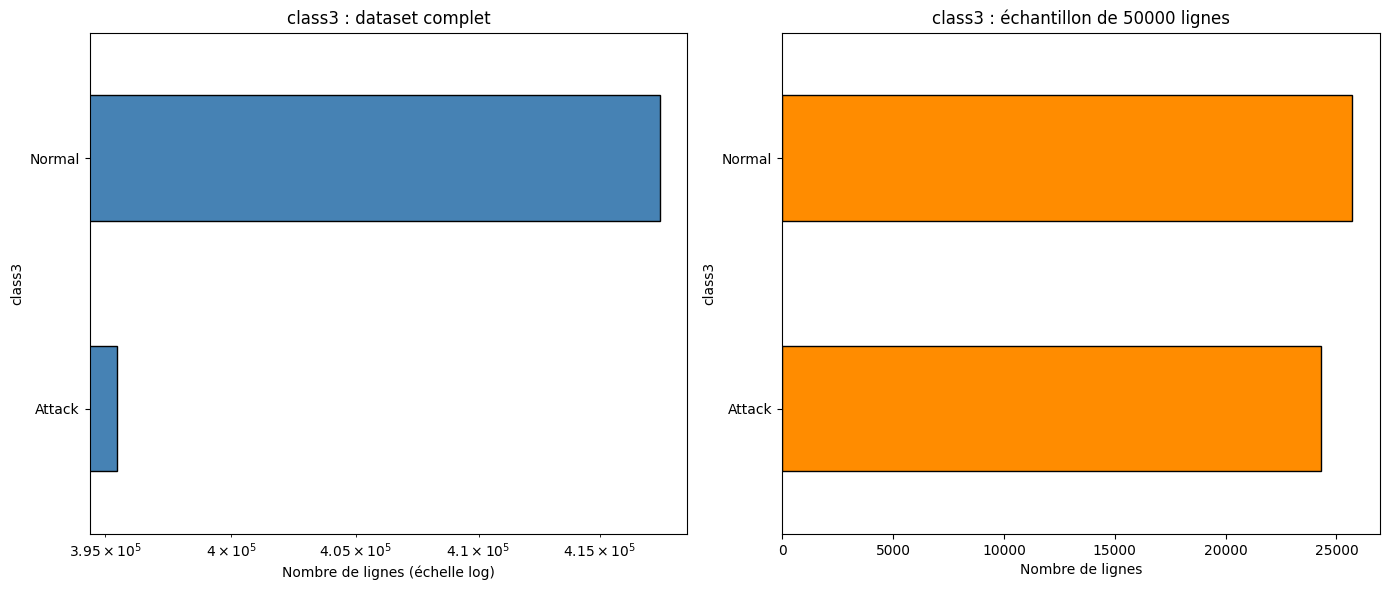

In [14]:
# Répartition de class3 : dataset complet (après nettoyage) et échantillon de 50000 lignes

# Sécurité : y est normalement défini dans la cellule qui crée X et y
if "y" not in globals():
    y = data_small["class3"]

complet = data["class3"].value_counts()   # dataset complet (et non data_small)
echant = y.value_counts()                 # échantillon de 50000 lignes

tab_classes = pd.DataFrame({
    "Dataset complet": complet,
    "% complet": (complet / complet.sum() * 100).round(2),
    "Échantillon": echant,
    "% échantillon": (echant / echant.sum() * 100).round(2),
}).fillna(0)
print(tab_classes.sort_values("Dataset complet", ascending=False))

# Rapport entre la plus grande et la plus petite classe de l'échantillon
print("\nNombre de classes :", y.nunique())
print("Rapport de déséquilibre (échantillon) :", round(echant.max() / echant.min(), 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

complet.sort_values().plot(kind="barh", ax=axes[0], color="steelblue", edgecolor="k")
axes[0].set_title("class3 : dataset complet")
axes[0].set_xlabel("Nombre de lignes (échelle log)")
axes[0].set_xscale("log")   # l'échelle log permet de voir aussi les classes rares

echant.sort_values().plot(kind="barh", ax=axes[1], color="darkorange", edgecolor="k")
axes[1].set_title("class3 : échantillon de 50000 lignes")
axes[1].set_xlabel("Nombre de lignes")

plt.tight_layout()
plt.show()

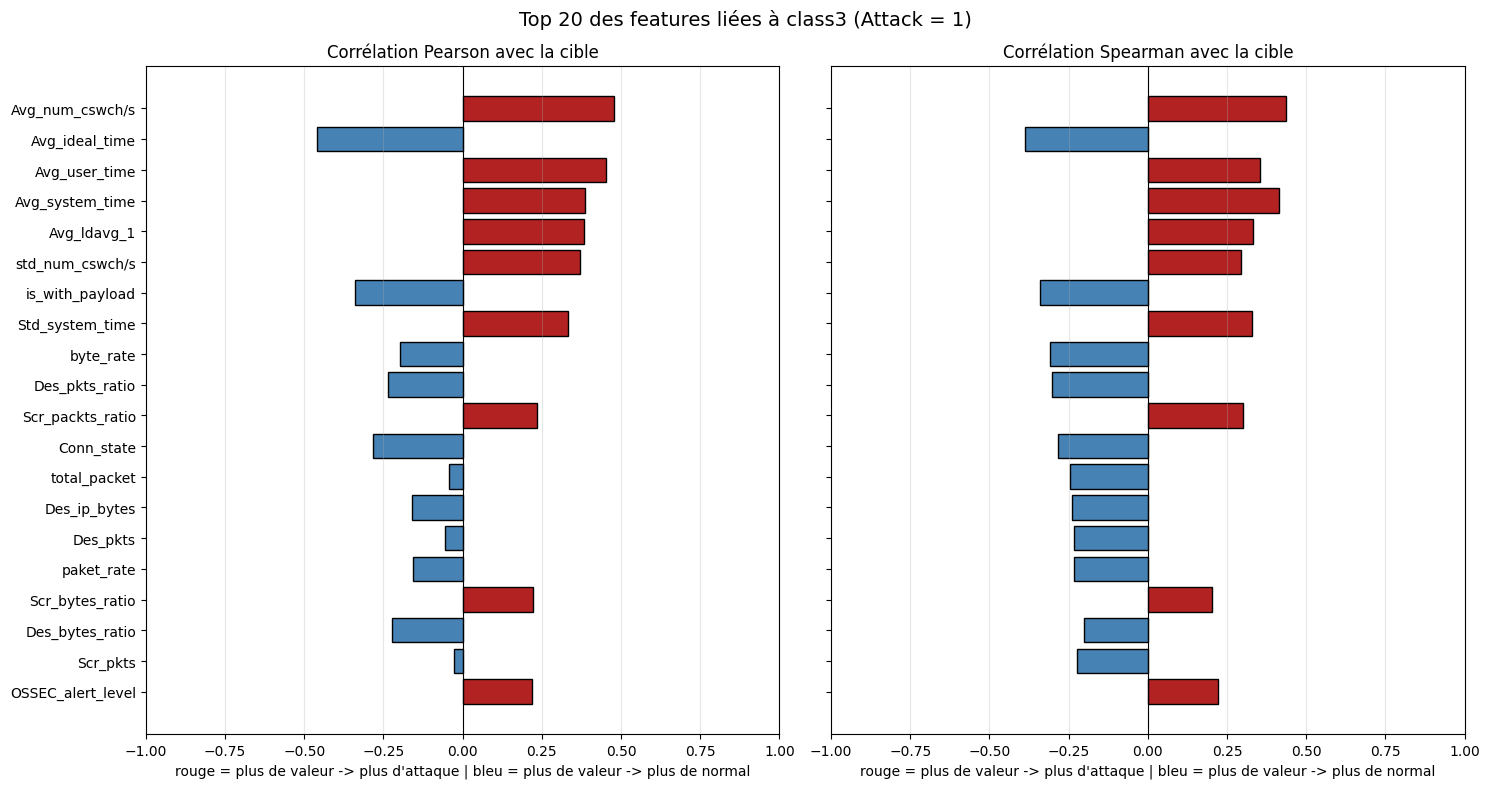

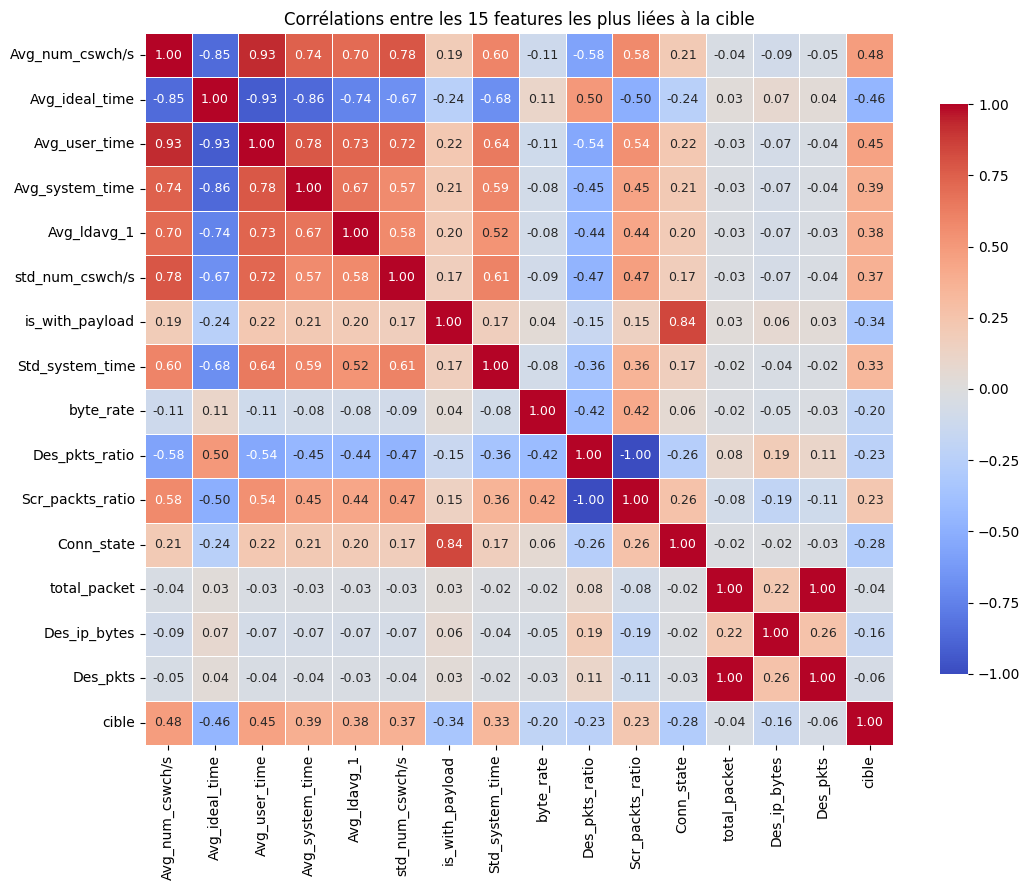

Nombre de paires redondantes : 23
       feature_1         feature_2  corrélation
 Scr_bytes_ratio   Des_bytes_ratio        1.000
Scr_packts_ratio    Des_pkts_ratio        1.000
 Succesful_login  Process_activity        0.999
    Des_ip_bytes       total_bytes        0.998
 Succesful_login     is_privileged        0.998
Process_activity     is_privileged        0.998
      Is_SYN_ACK       is_pure_ack        0.996
       Des_bytes       total_bytes        0.996
        Des_pkts      total_packet        0.995
        Scr_pkts      total_packet        0.995
       Des_bytes      Des_ip_bytes        0.992
     is_syn_only        FIN or RST        0.982
        Scr_pkts          Des_pkts        0.980
     OSSEC_alert OSSEC_alert_level        0.978
      paket_rate         byte_rate        0.975
    Scr_ip_bytes      total_packet        0.967
   Login_attempt   Succesful_login        0.964
        Scr_pkts      Scr_ip_bytes        0.964
   Login_attempt  Process_activity        0.964
   Log

In [15]:
# ---------- Préparation ----------
df_corr = data_small.select_dtypes("number").copy()
df_corr = df_corr.loc[:, df_corr.nunique() > 1]          # enlève les colonnes constantes
y_bin = (data_small["class3"] == "Attack").astype(int)   # Attack = 1, Normal = 0

# Pearson = lien linéaire ; Spearman = lien monotone, plus fiable sur vos features très asymétriques
tab = pd.DataFrame({
    "Pearson":  df_corr.corrwith(y_bin),
    "Spearman": df_corr.corrwith(y_bin, method="spearman"),
})
tab["force"] = tab.abs().max(axis=1)
tab = tab.sort_values("force", ascending=False)

# ---------- 1) Corrélation de chaque feature avec la cible (le graphique le plus utile) ----------
top = tab.head(20).iloc[::-1]                      # 20 features les plus liées à la cible
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
for ax, col in zip(axes, ["Pearson", "Spearman"]):
    couleurs = ["firebrick" if v > 0 else "steelblue" for v in top[col]]
    ax.barh(top.index, top[col], color=couleurs, edgecolor="k")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(f"Corrélation {col} avec la cible")
    ax.set_xlabel("rouge = plus de valeur -> plus d'attaque | bleu = plus de valeur -> plus de normal")
    ax.grid(axis="x", alpha=0.3)
plt.suptitle("Top 20 des features liées à class3 (Attack = 1)", fontsize=14)
plt.tight_layout()
plt.show()

# ---------- 2) Heatmap réduite : seulement les 15 features les plus liées à la cible ----------
feats = tab.head(15).index.tolist()
corr_top = df_corr[feats].assign(cible=y_bin).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot_kws={"size": 9}, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Corrélations entre les 15 features les plus liées à la cible")
plt.tight_layout()
plt.show()

# ---------- 3) Tableau des features redondantes (|corr| > 0.95) : candidates à la suppression ----------
corr_all = df_corr.corr().abs()
triu = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
paires = triu.stack().rename("corrélation").reset_index()
paires.columns = ["feature_1", "feature_2", "corrélation"]
paires = paires[paires["corrélation"] > 0.95].sort_values("corrélation", ascending=False)
print("Nombre de paires redondantes :", len(paires))
print(paires.round(3).to_string(index=False))

# ---------- 4) Alerte fuite de données ----------
suspectes = tab[tab["force"] > 0.9].index.tolist()
print("\nFeatures avec |corr| > 0.9 avec la cible (à vérifier, risque de fuite) :", suspectes)

In [16]:
# Les colonnes binaires (0/1) n'ont pas d'asymétrie utile à regarder : je les mets à part.

# Sécurité : X est normalement défini dans la cellule qui retire class1, class2, class3
if "X" not in globals():
    X = data_small.drop(columns=["class1", "class2", "class3"])

num_all = X.select_dtypes("number").columns.tolist()
cont = [c for c in num_all if X[c].nunique() > 2]
binaires = [c for c in num_all if X[c].nunique() <= 2]

print("Features continues :", len(cont))
print("Features binaires  :", len(binaires))
print("Catégorielles      :", X.select_dtypes(exclude="number").columns.tolist())

# Fonction pour afficher les graphiques en grille : 9 par page (3 par ligne) pour rester lisible
def grille(cols, tracer, titre, par_page=9, ncols=3):
    for debut in range(0, len(cols), par_page):
        sous = cols[debut:debut + par_page]
        nrows = int(np.ceil(len(sous) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))
        axes = np.array(axes).reshape(-1)
        for ax, c in zip(axes, sous):
            tracer(ax, c)
            ax.tick_params(axis="x", labelsize=8, rotation=30)   # évite le chevauchement des valeurs sur l'axe x
            ax.tick_params(axis="y", labelsize=8)
        for ax in axes[len(sous):]:
            ax.axis("off")
        fig.suptitle(f"{titre} ({debut + 1} à {debut + len(sous)} sur {len(cols)})", fontsize=15)
        plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3, w_pad=3)   # espace entre les graphiques + place pour le titre
        plt.show()

Features continues : 45
Features binaires  : 14
Catégorielles      : ['Protocol', 'Service']


In [17]:
# Skew : 0 = symétrique ; > 0 = queue vers la droite (quelques très grandes valeurs) ; < 0 = queue vers la gauche
skew_tab = X[cont].skew().sort_values(key=abs, ascending=False).round(2)

def lire_skew(s):
    a = abs(s)
    if a < 0.5:
        return "Symétrique"
    elif a < 1:
        return "Asymétrie modérée"
    return "Très asymétrique"

resume_skew = pd.DataFrame({"Skew": skew_tab, "Lecture": skew_tab.apply(lire_skew)})
print(resume_skew)
print("\nColonnes très asymétriques (|skew| >= 1) :", (skew_tab.abs() >= 1).sum(), "sur", len(skew_tab))

                     Skew            Lecture
Scr_pkts           161.89   Très asymétrique
total_packet       157.69   Très asymétrique
Des_pkts           149.95   Très asymétrique
Scr_ip_bytes       143.06   Très asymétrique
missed_bytes       137.79   Très asymétrique
Duration            53.11   Très asymétrique
Scr_bytes           32.44   Très asymétrique
Avg_rtps            28.92   Très asymétrique
Avg_tps             25.60   Très asymétrique
Std_kbmemused       16.55   Très asymétrique
Avg_kbmemused      -12.84   Très asymétrique
Des_ip_bytes        12.26   Très asymétrique
Des_bytes           12.04   Très asymétrique
total_bytes         11.73   Très asymétrique
Std_ldavg_1          7.80   Très asymétrique
Std_tps              7.17   Très asymétrique
Std_rtps             6.83   Très asymétrique
byte_rate            5.99   Très asymétrique
paket_rate           5.27   Très asymétrique
OSSEC_alert_level    4.40   Très asymétrique
Std_num_proc/s       4.29   Très asymétrique
Avg_num_Pr

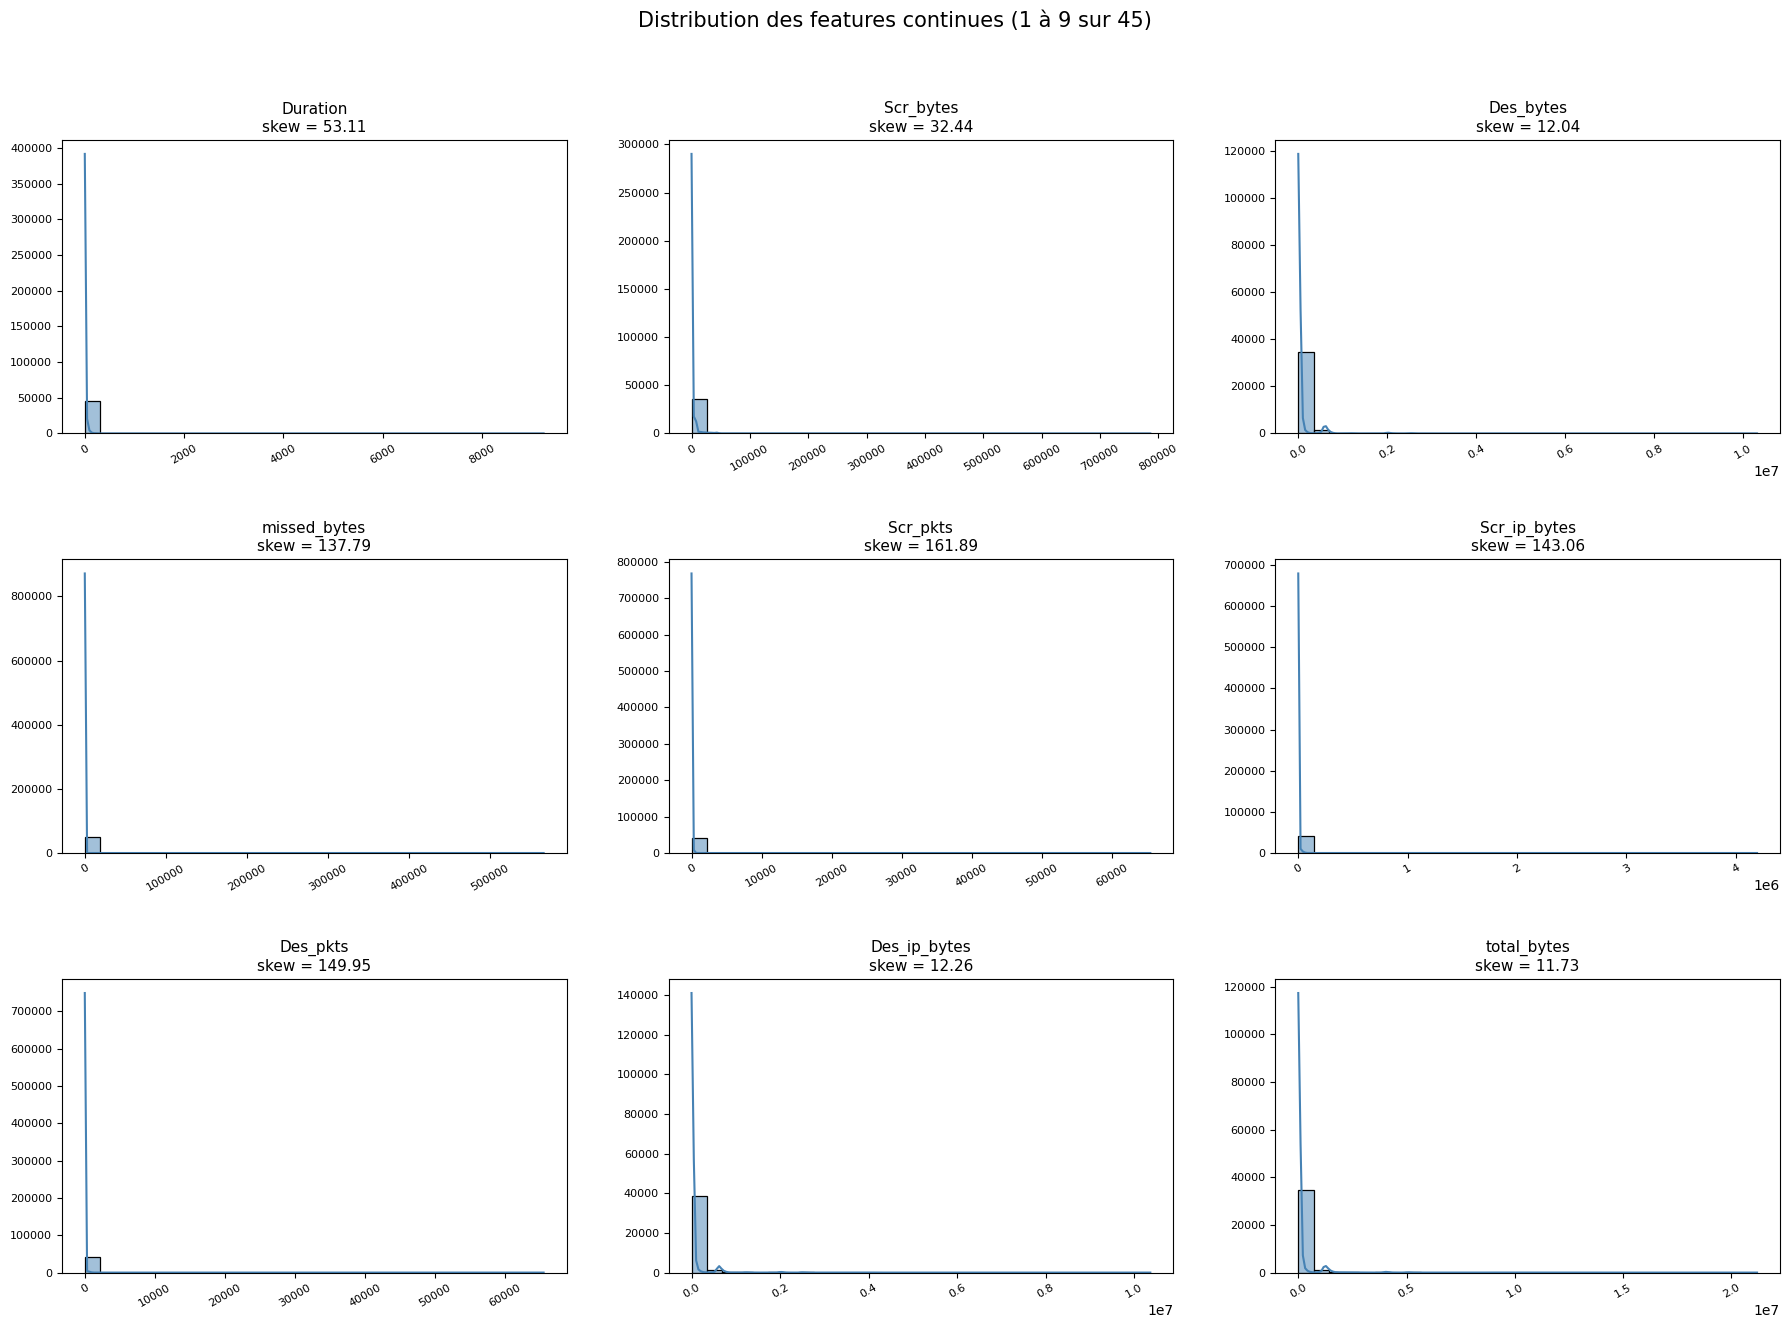

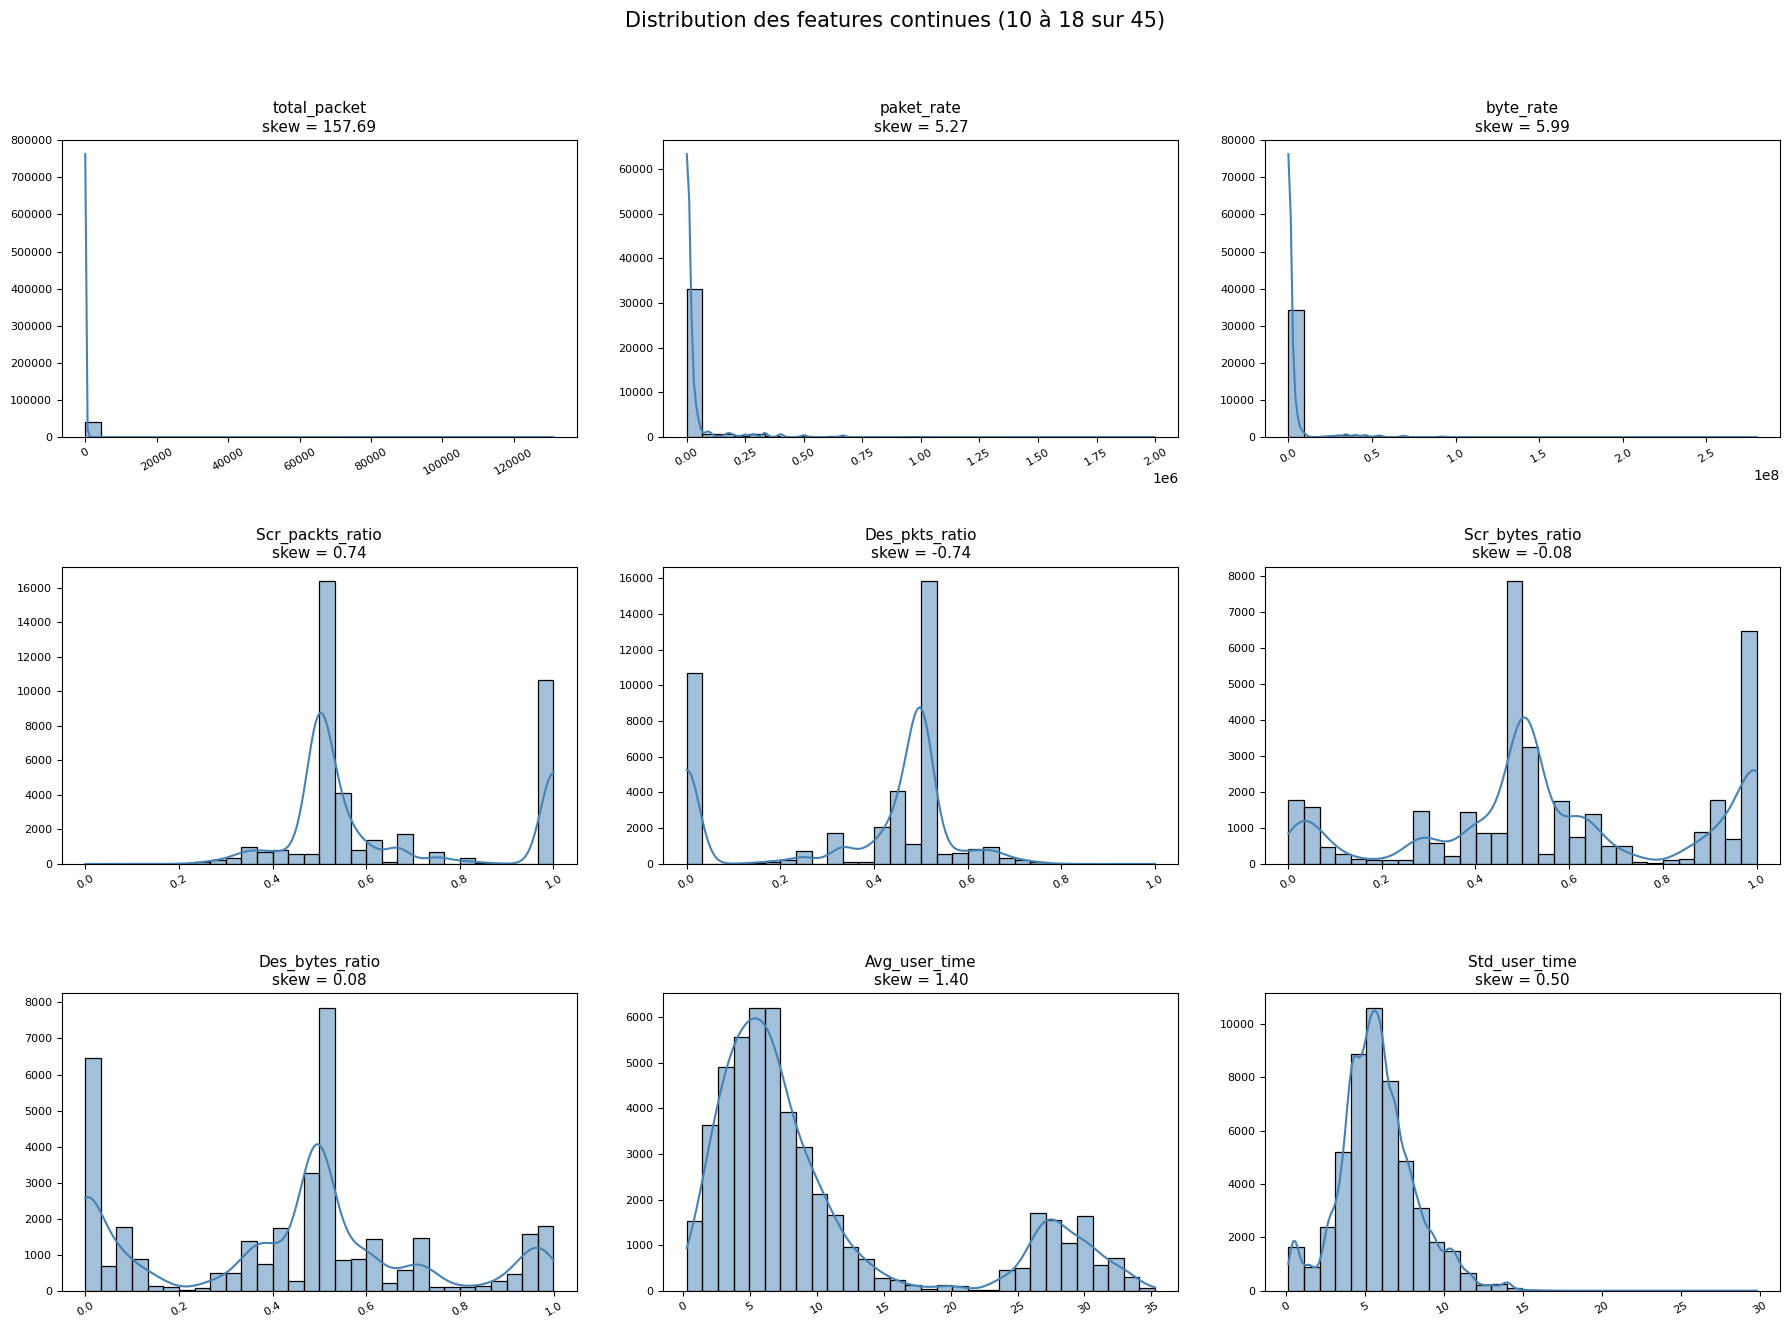

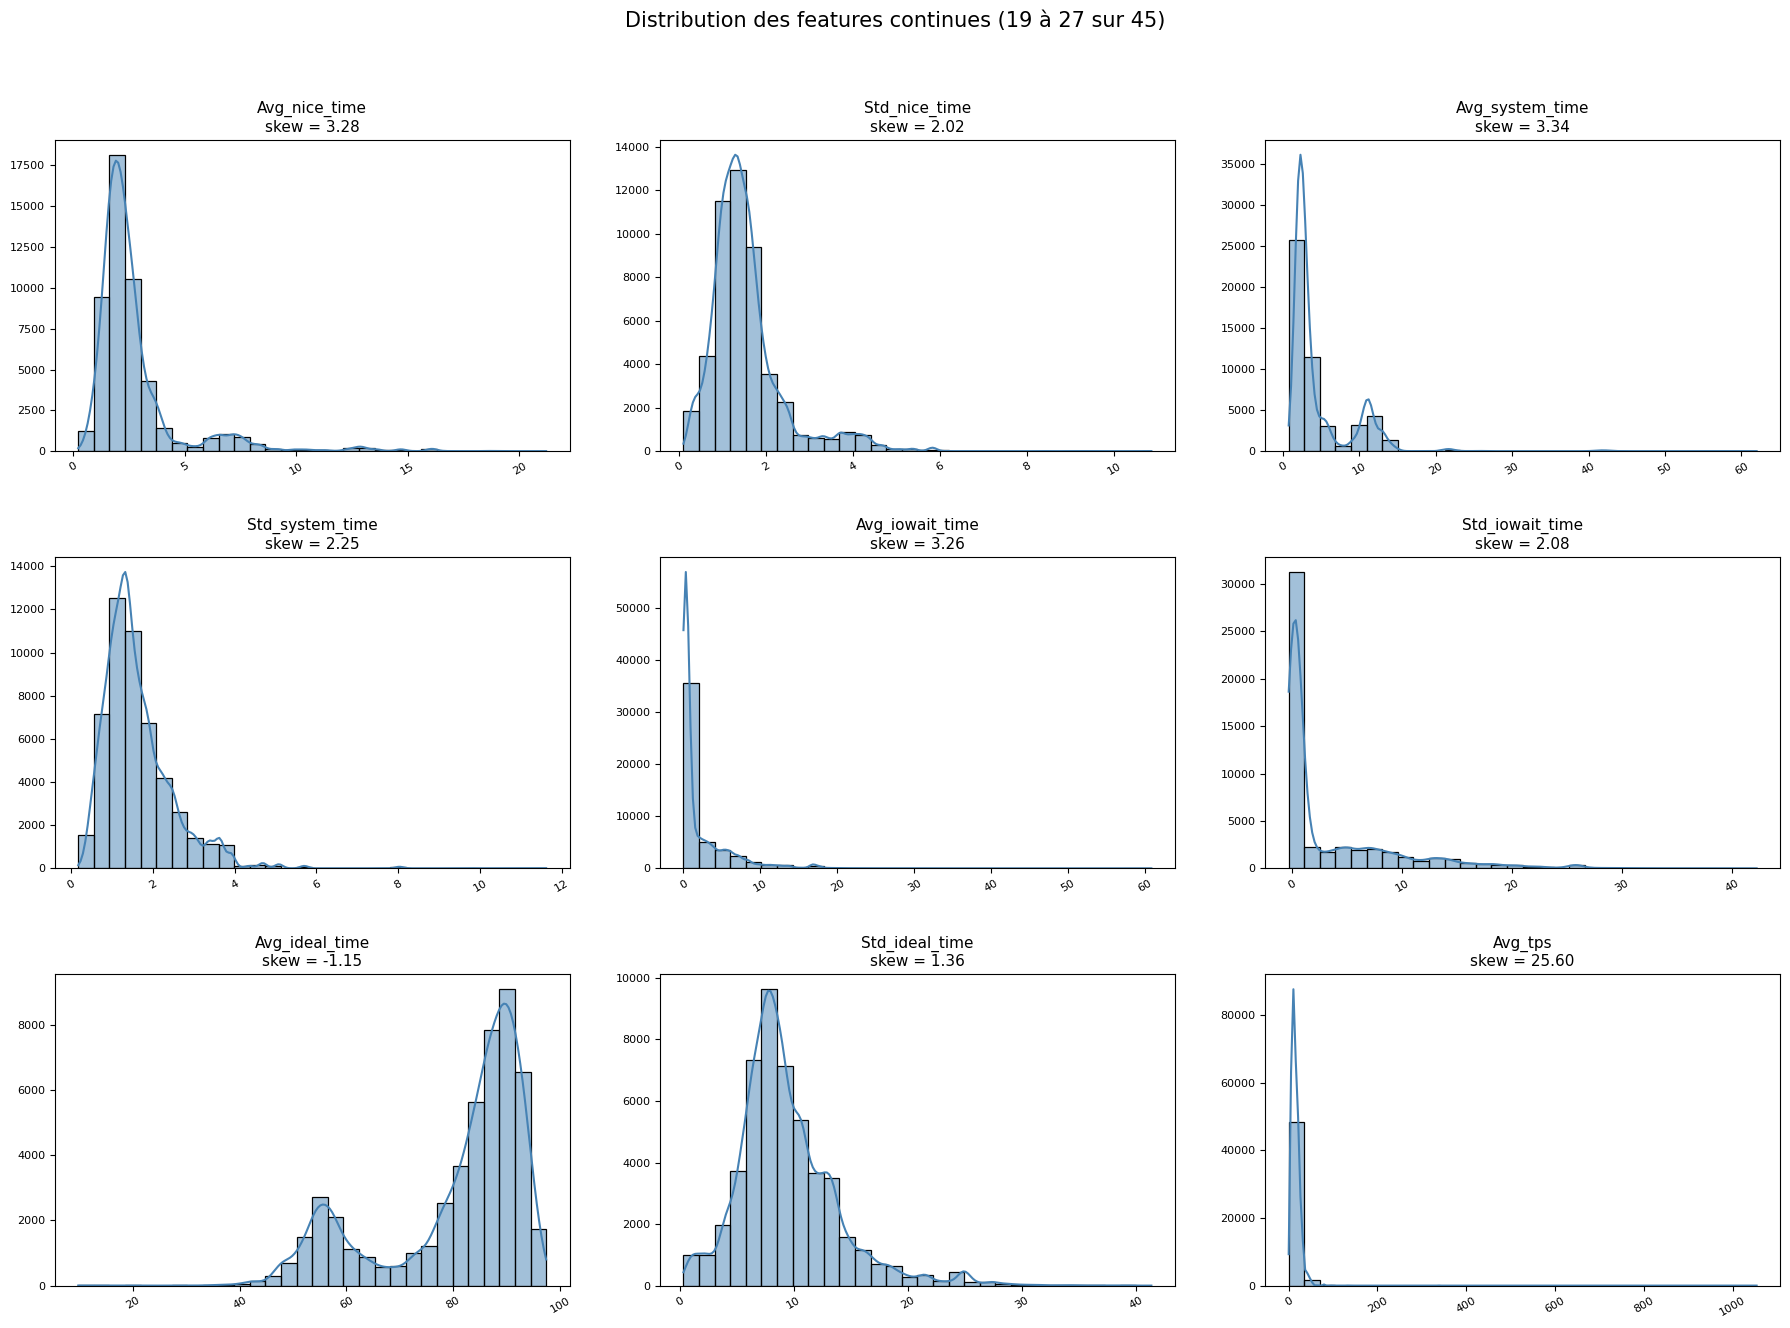

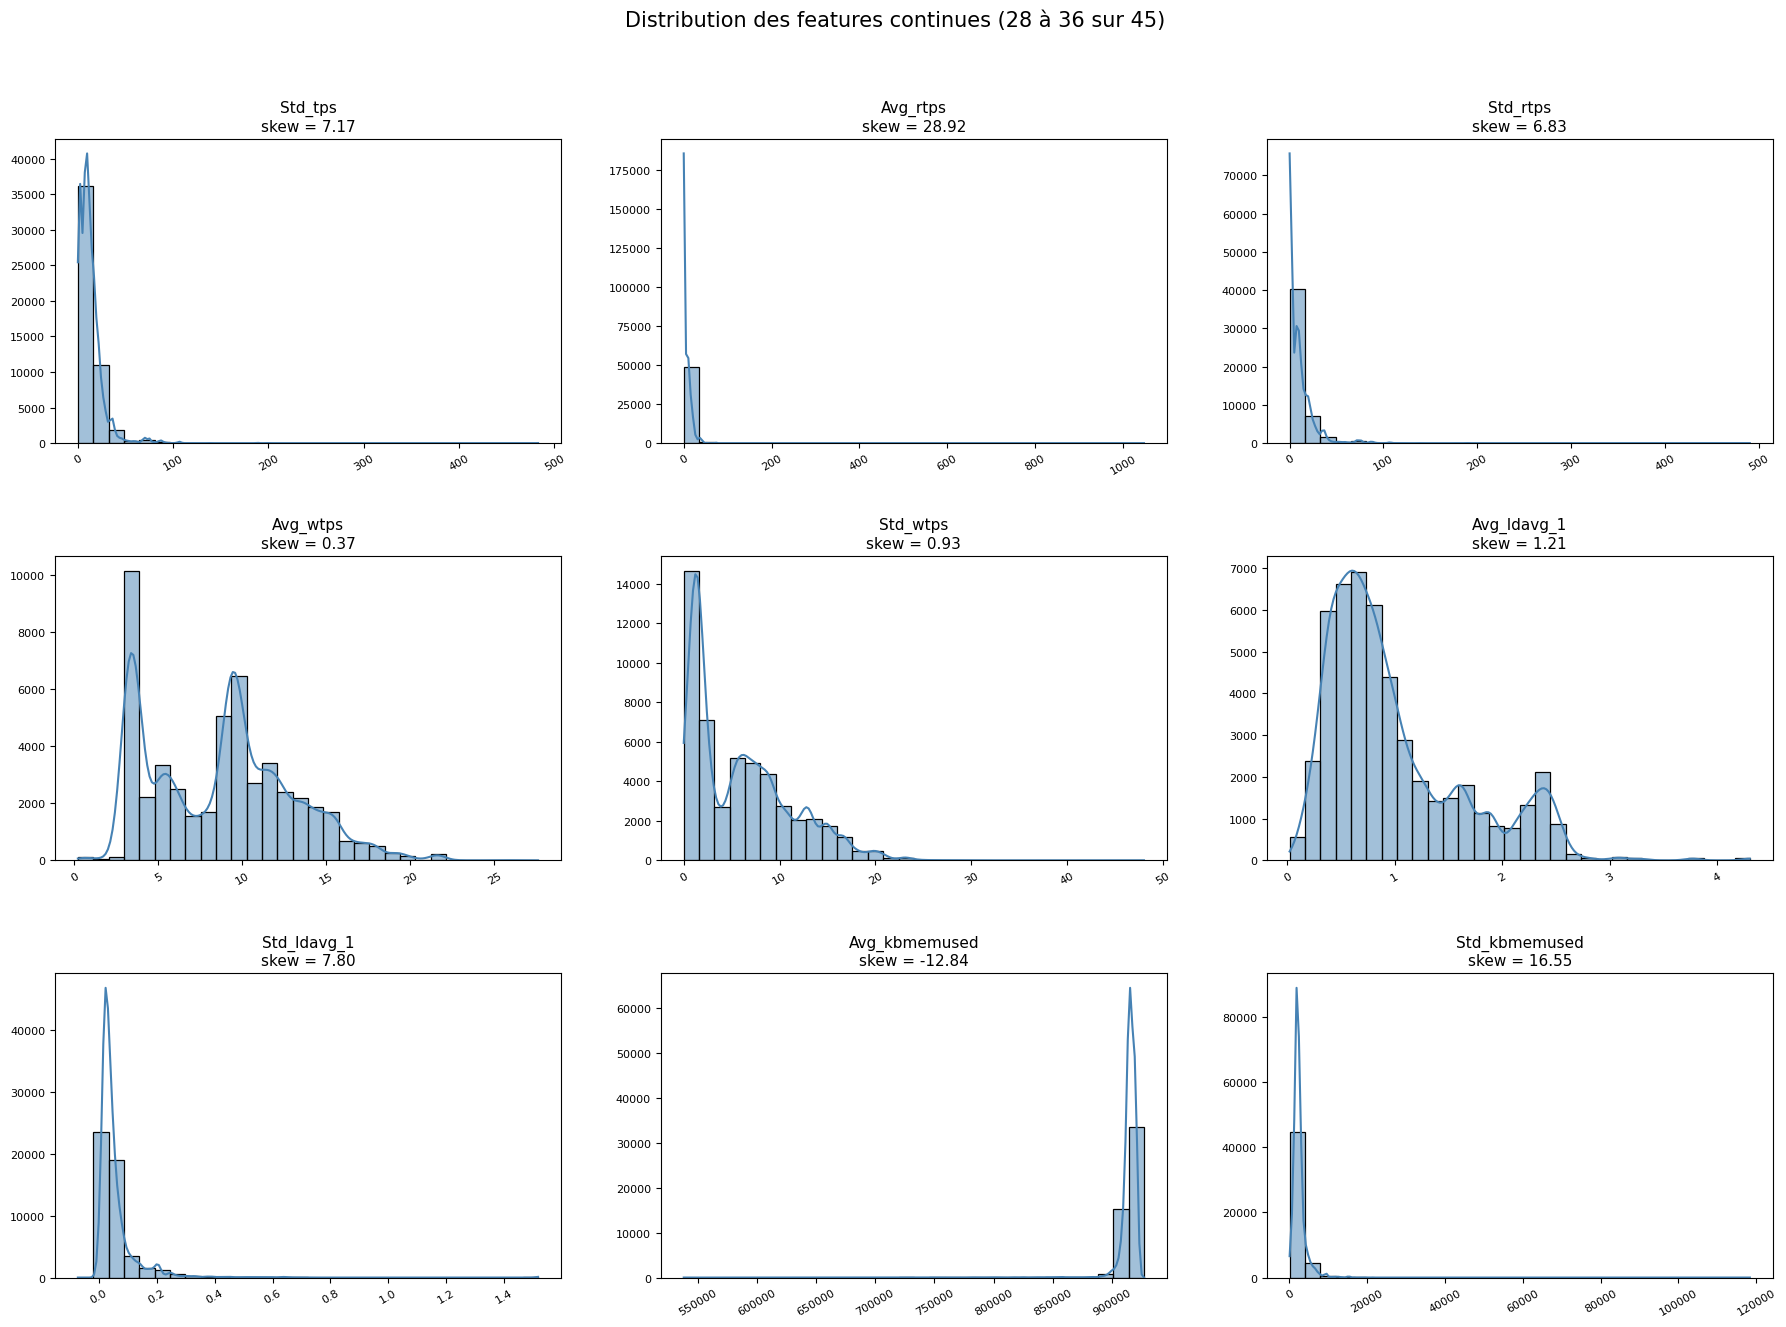

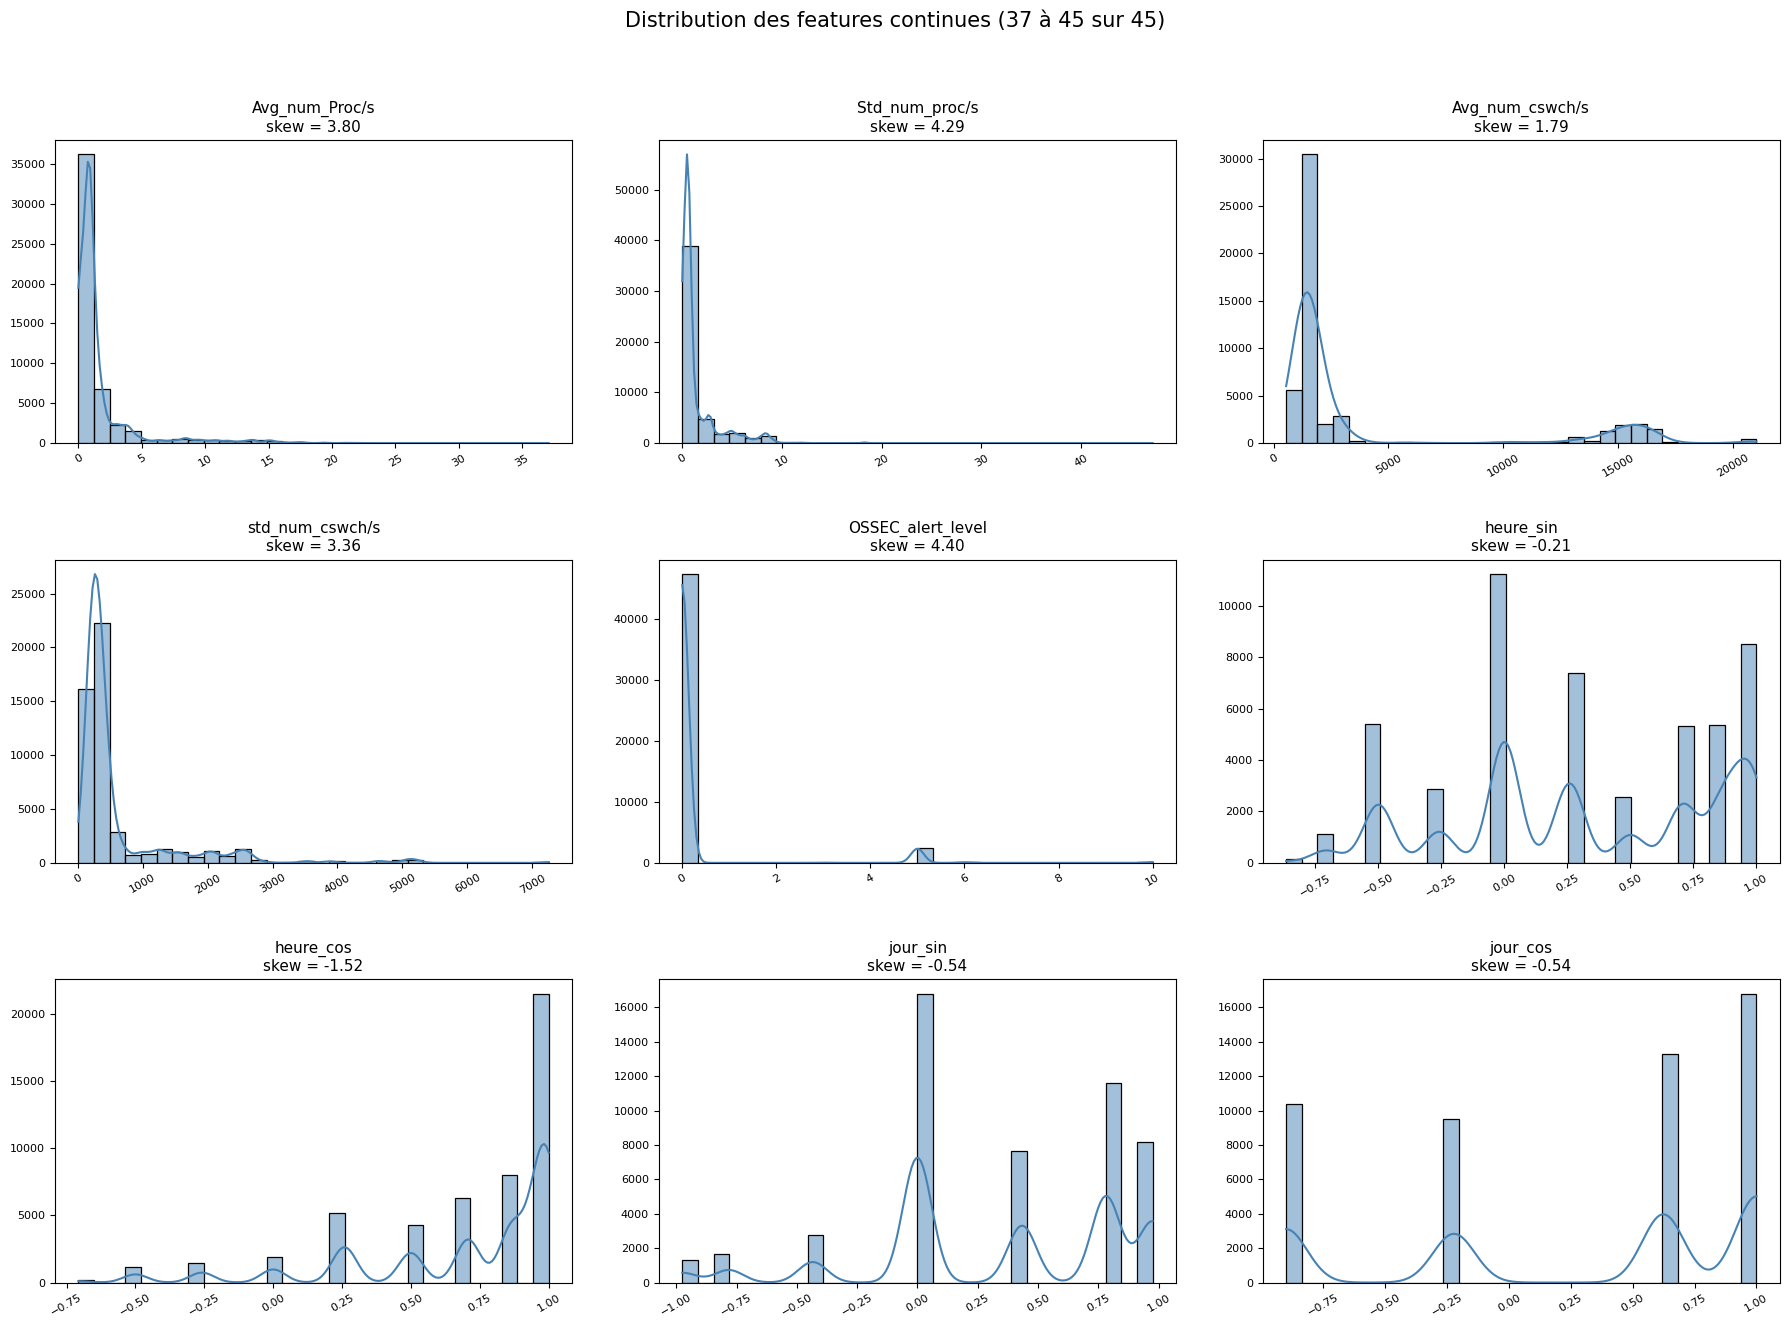

In [18]:
# Histogramme + courbe de densité pour chaque feature continue, avec son skew dans le titre
def tracer_hist(ax, c):
    sns.histplot(X[c].dropna(), kde=True, bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{c}\nskew = {X[c].skew():.2f}", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

grille(cont, tracer_hist, "Distribution des features continues")

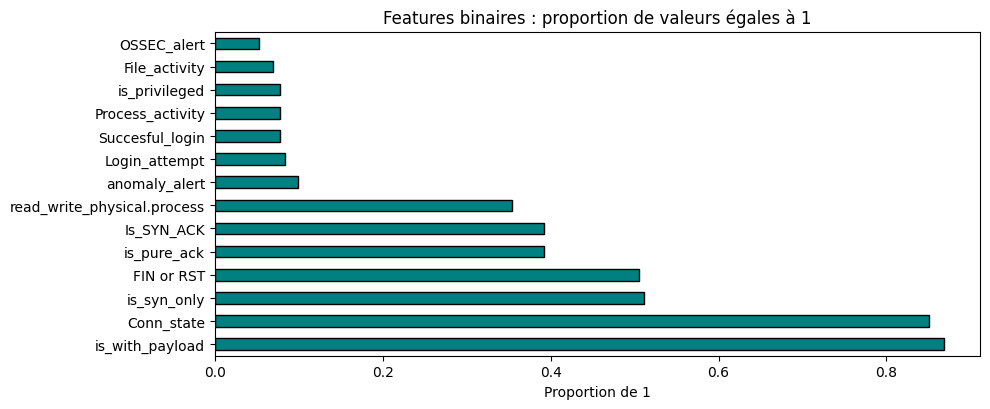

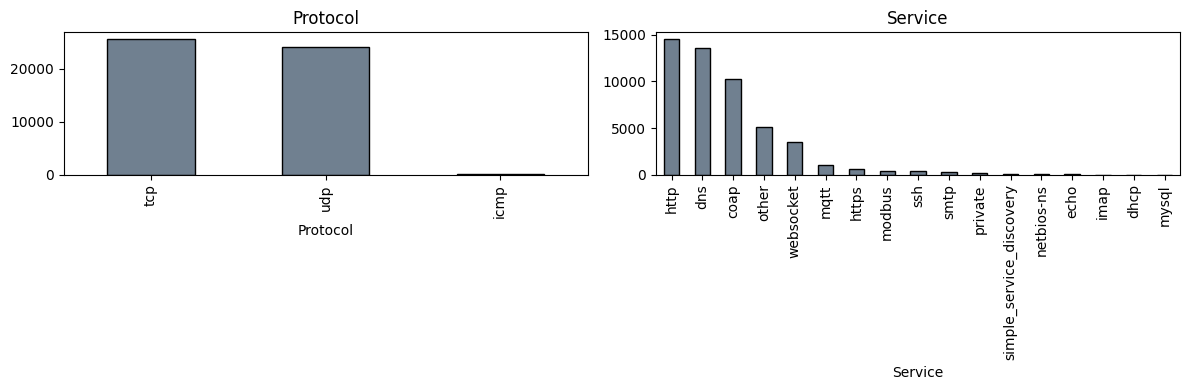

In [19]:
# Binaires : proportion de 0 et de 1
if len(binaires) > 0:
    prop = X[binaires].mean().sort_values(ascending=False).round(3)
    plt.figure(figsize=(10, max(3, 0.3 * len(prop))))
    prop.plot(kind="barh", color="teal", edgecolor="k")
    plt.xlabel("Proportion de 1")
    plt.title("Features binaires : proportion de valeurs égales à 1")
    plt.tight_layout()
    plt.show()

# Catégorielles : nombre de lignes par modalité
cats = X.select_dtypes(exclude="number").columns.tolist()
fig, axes = plt.subplots(1, len(cats), figsize=(6 * len(cats), 4))
axes = np.array(axes).reshape(-1)
for ax, c in zip(axes, cats):
    X[c].value_counts().plot(kind="bar", ax=ax, color="slategray", edgecolor="k")
    ax.set_title(c)
plt.tight_layout()
plt.show()

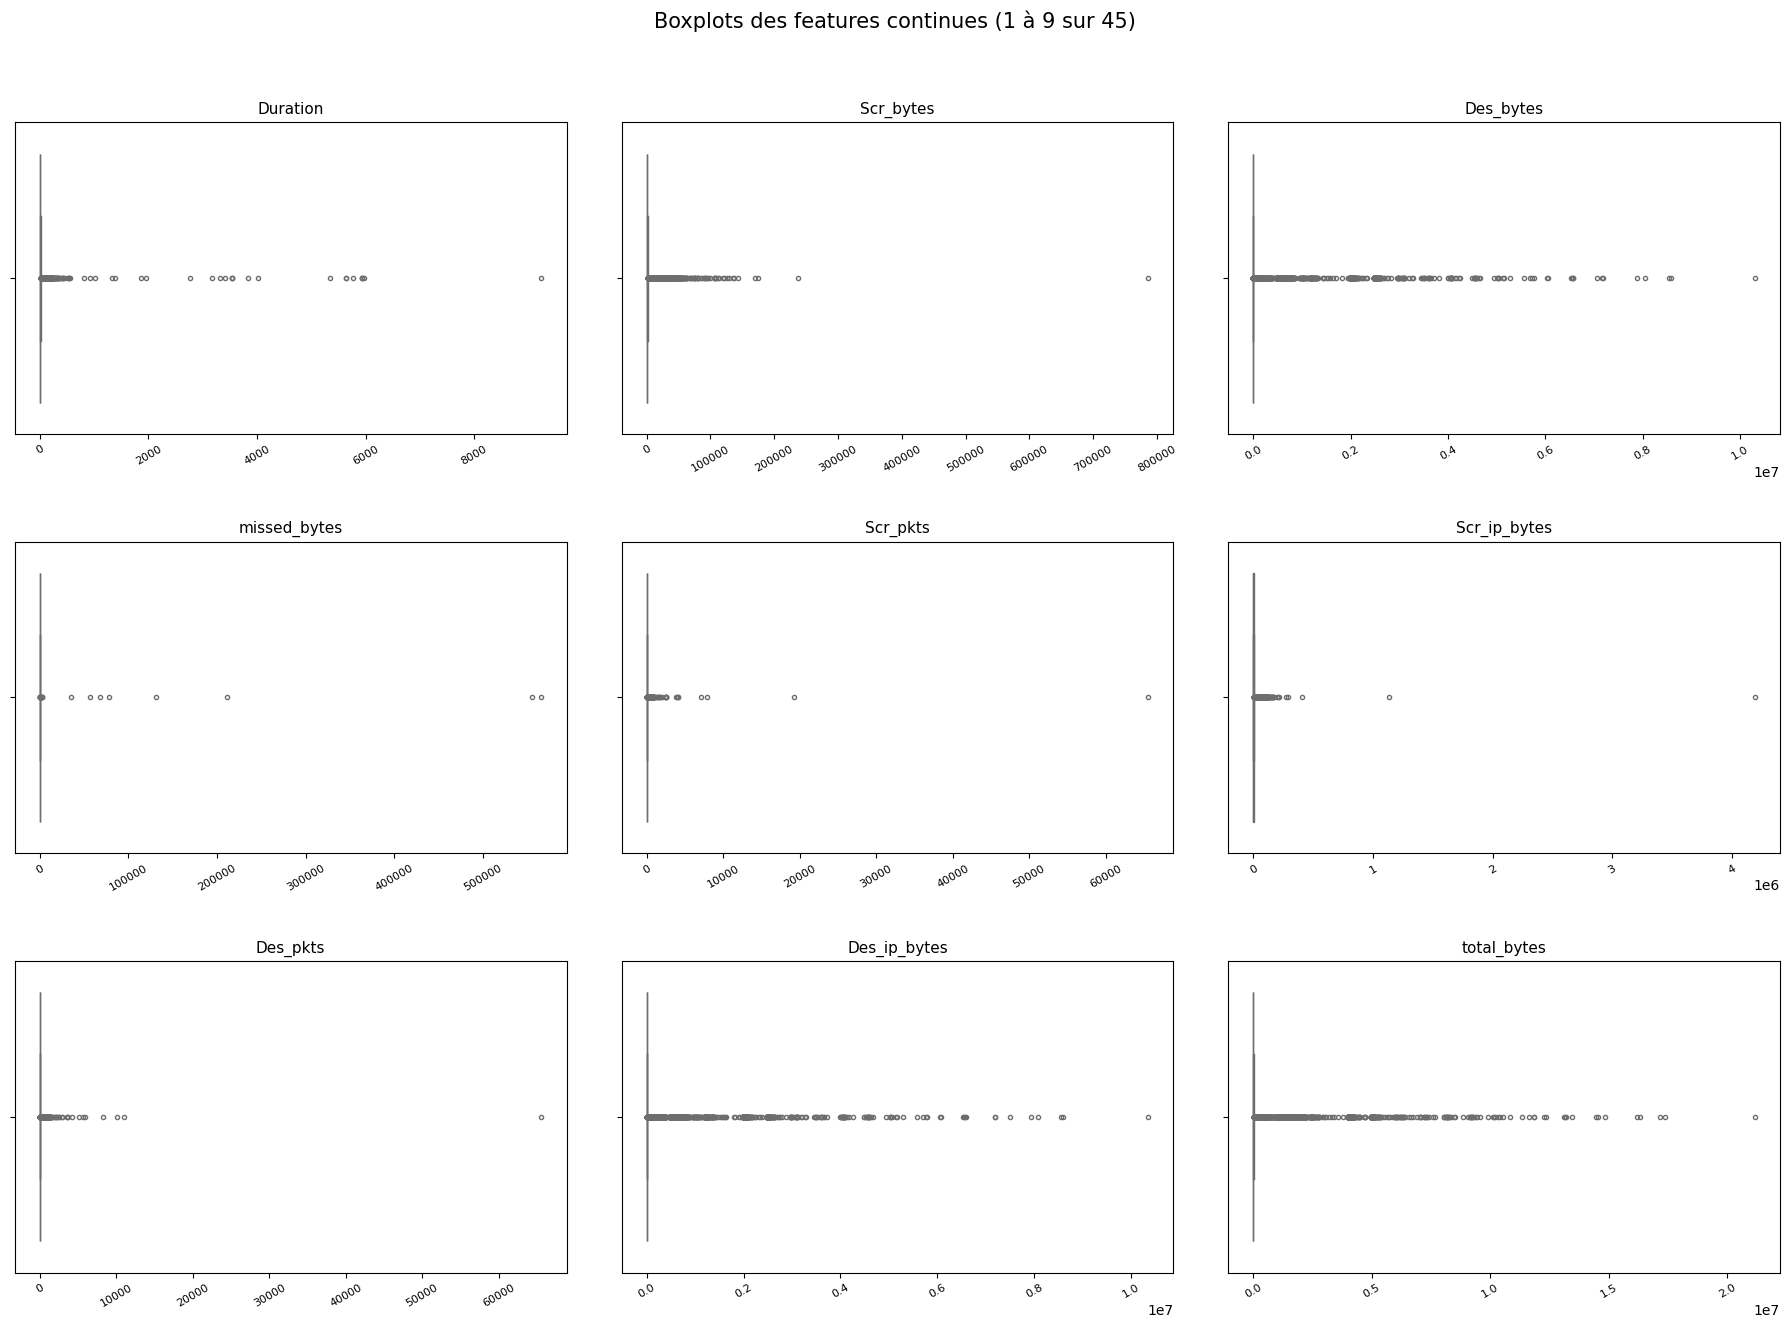

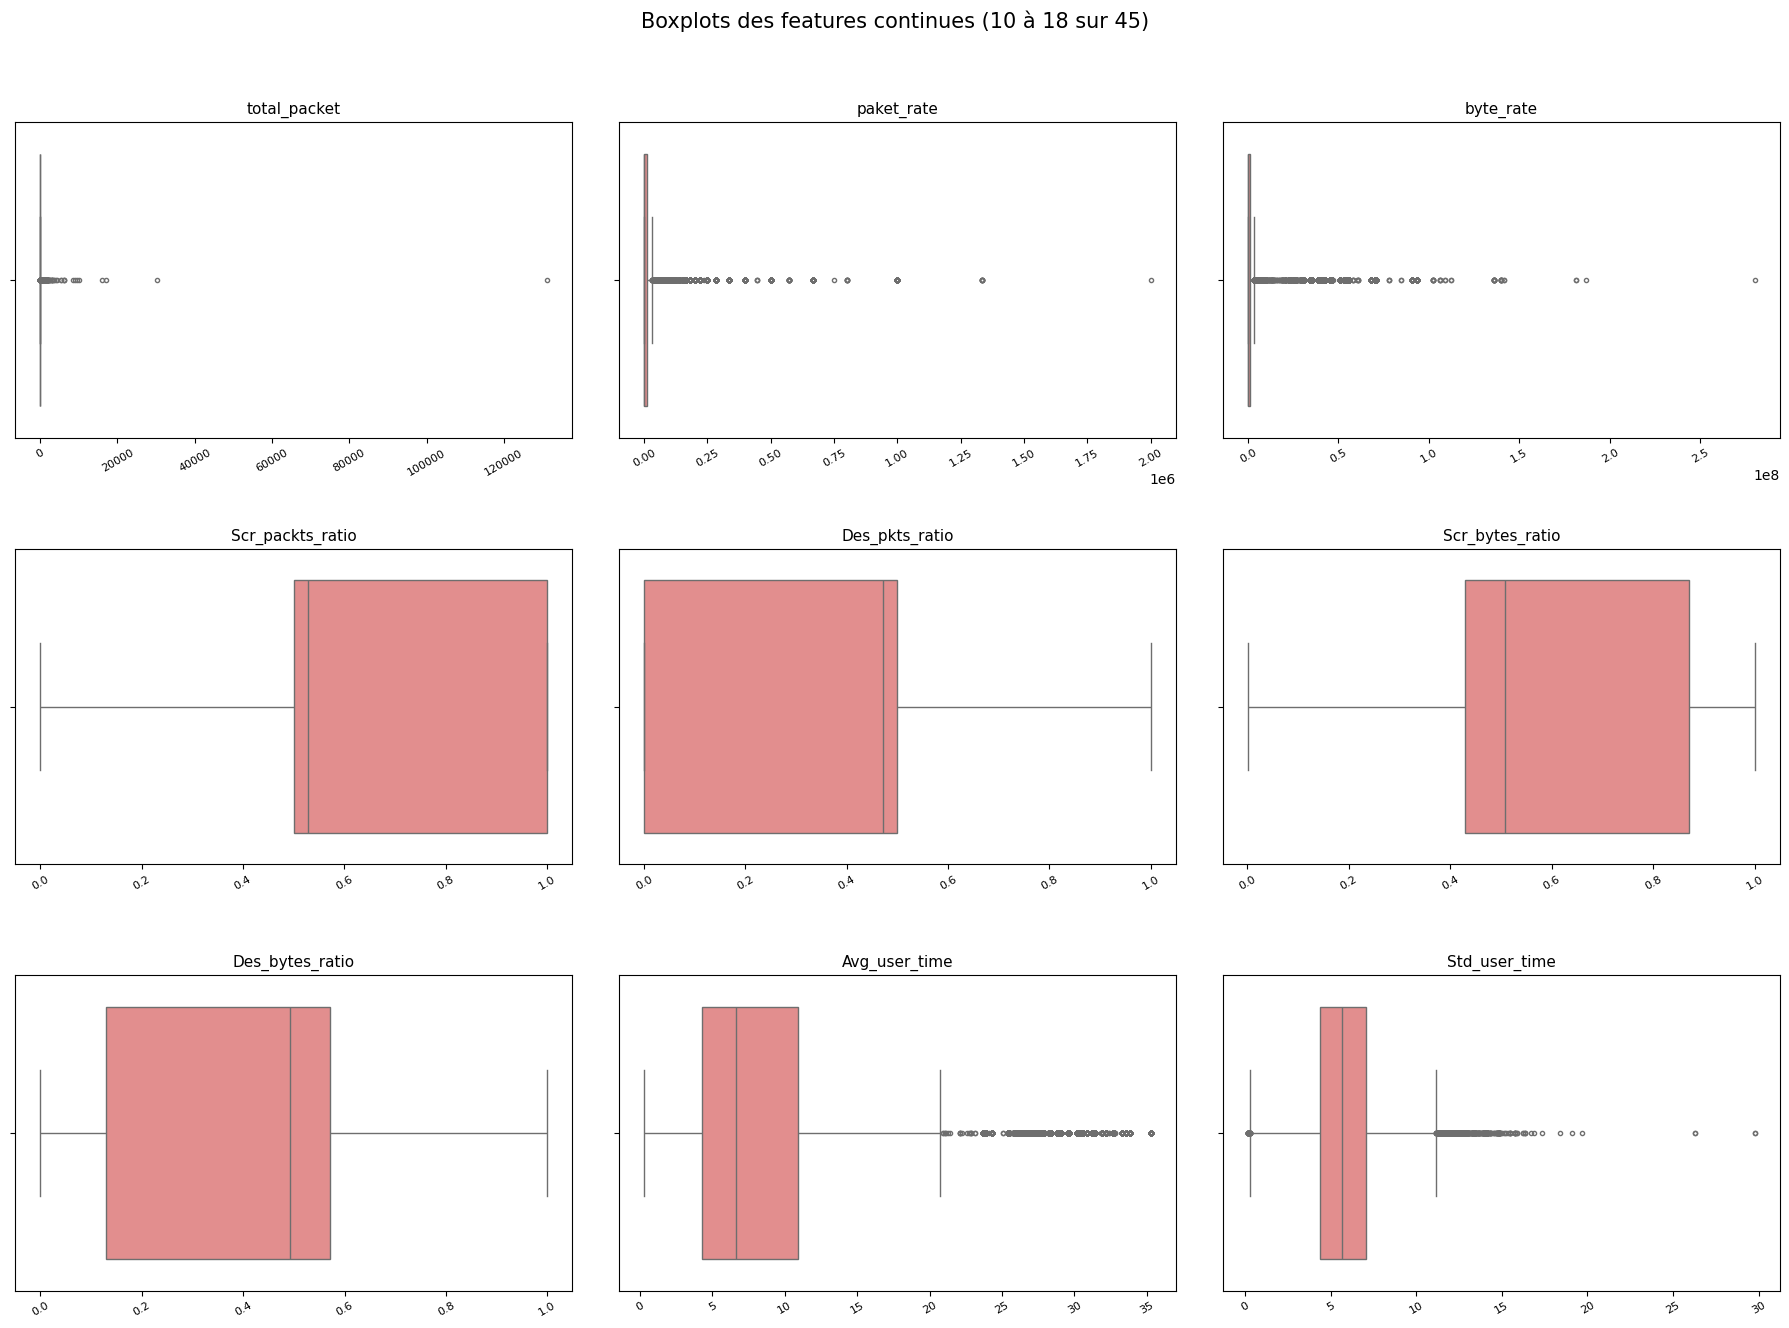

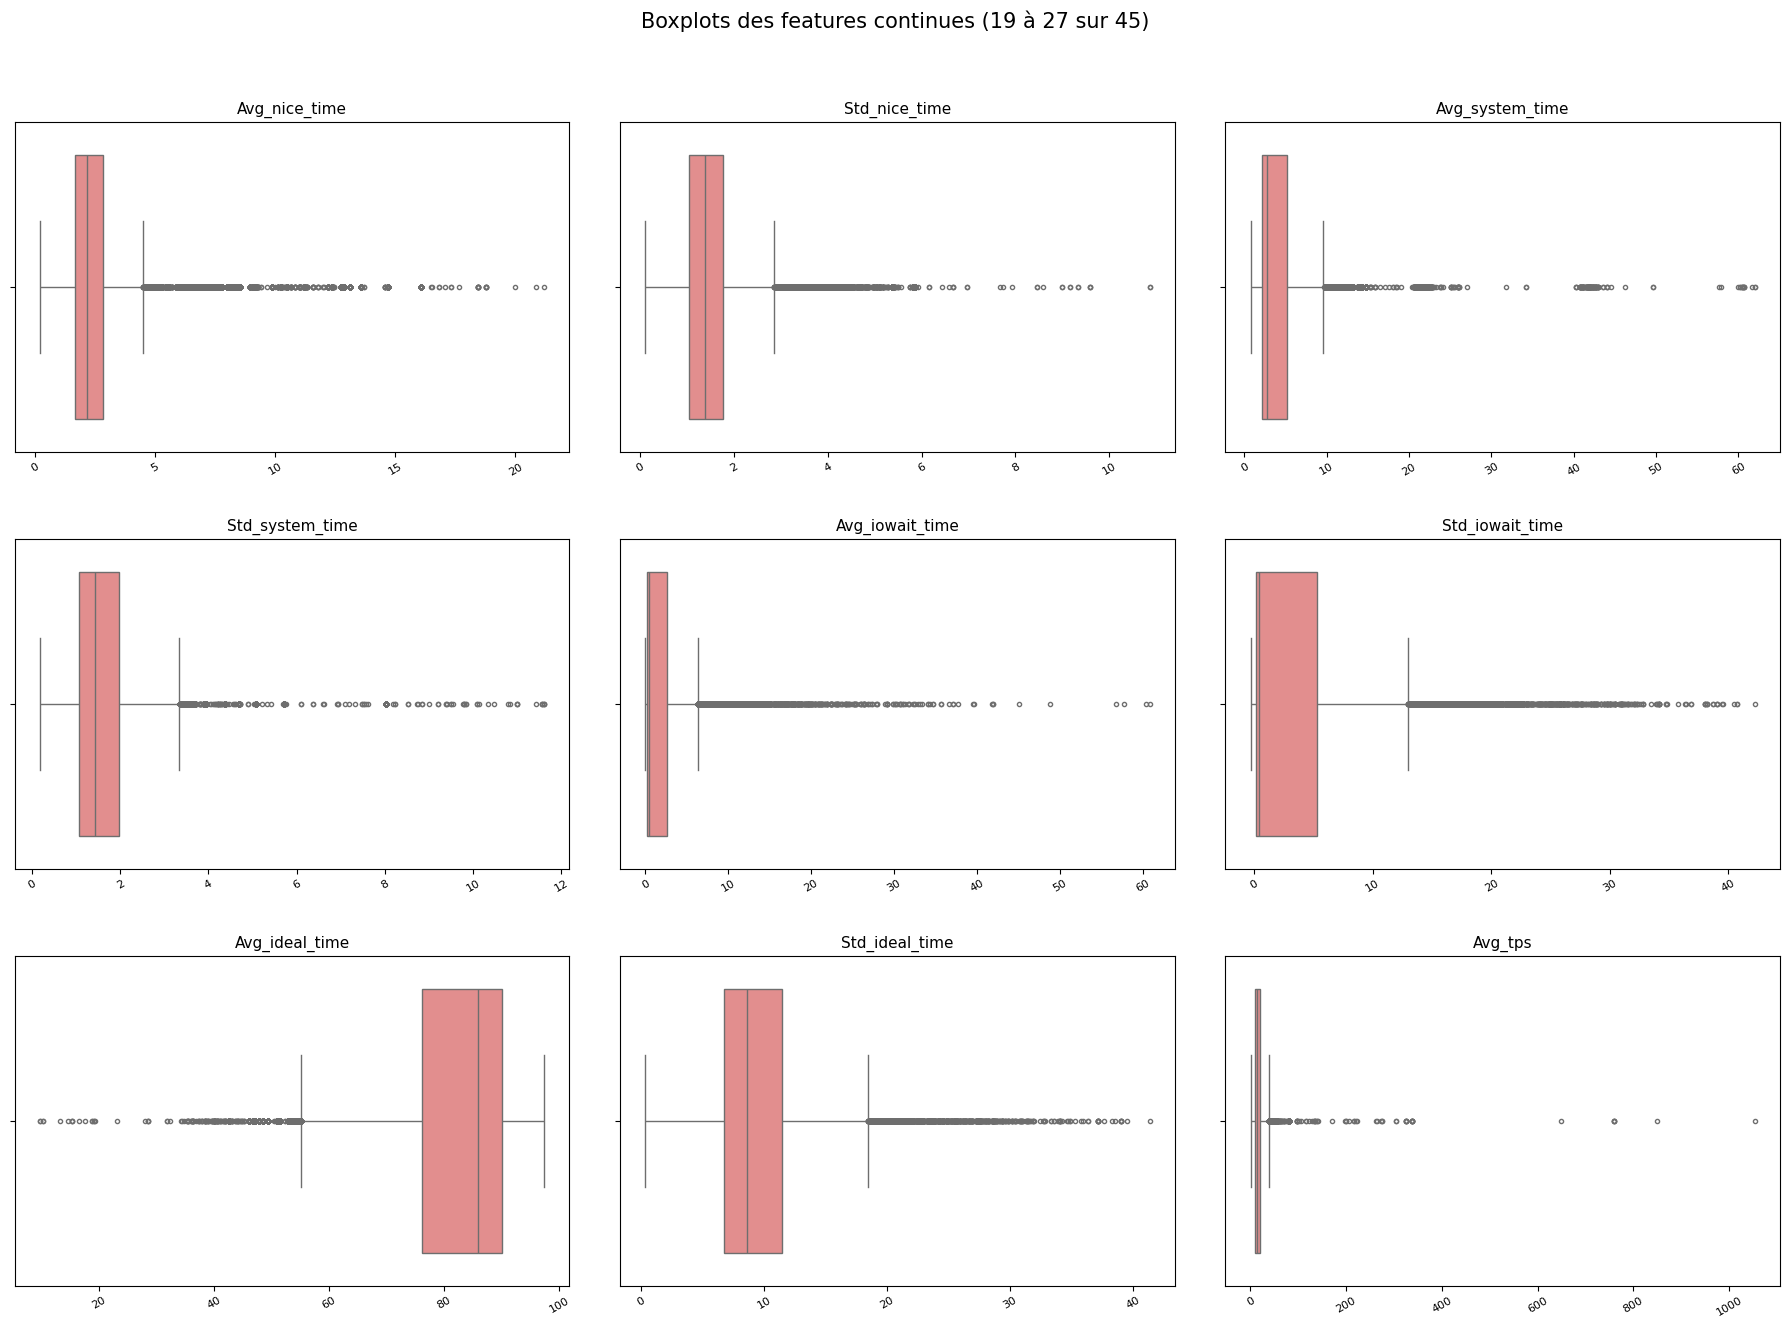

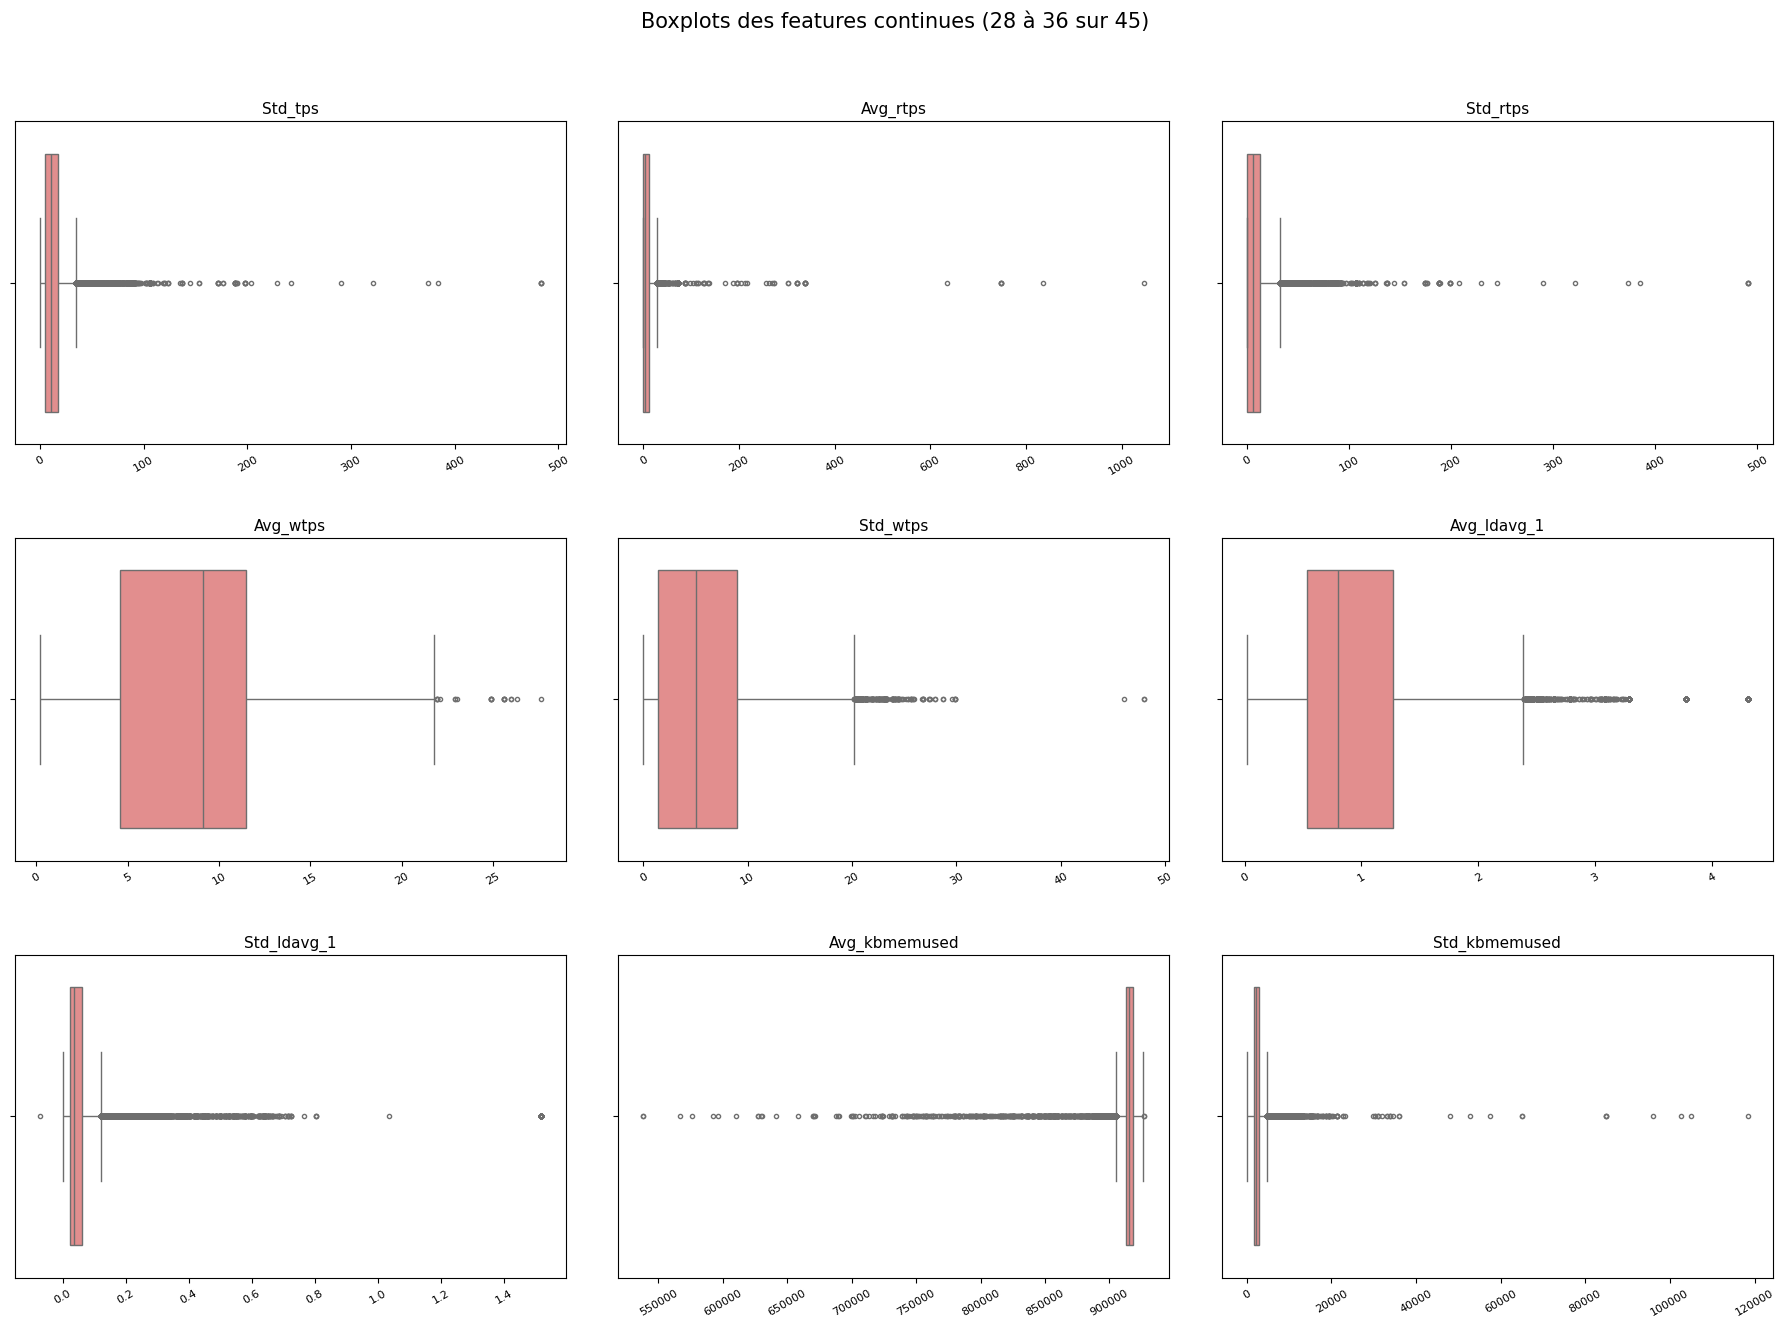

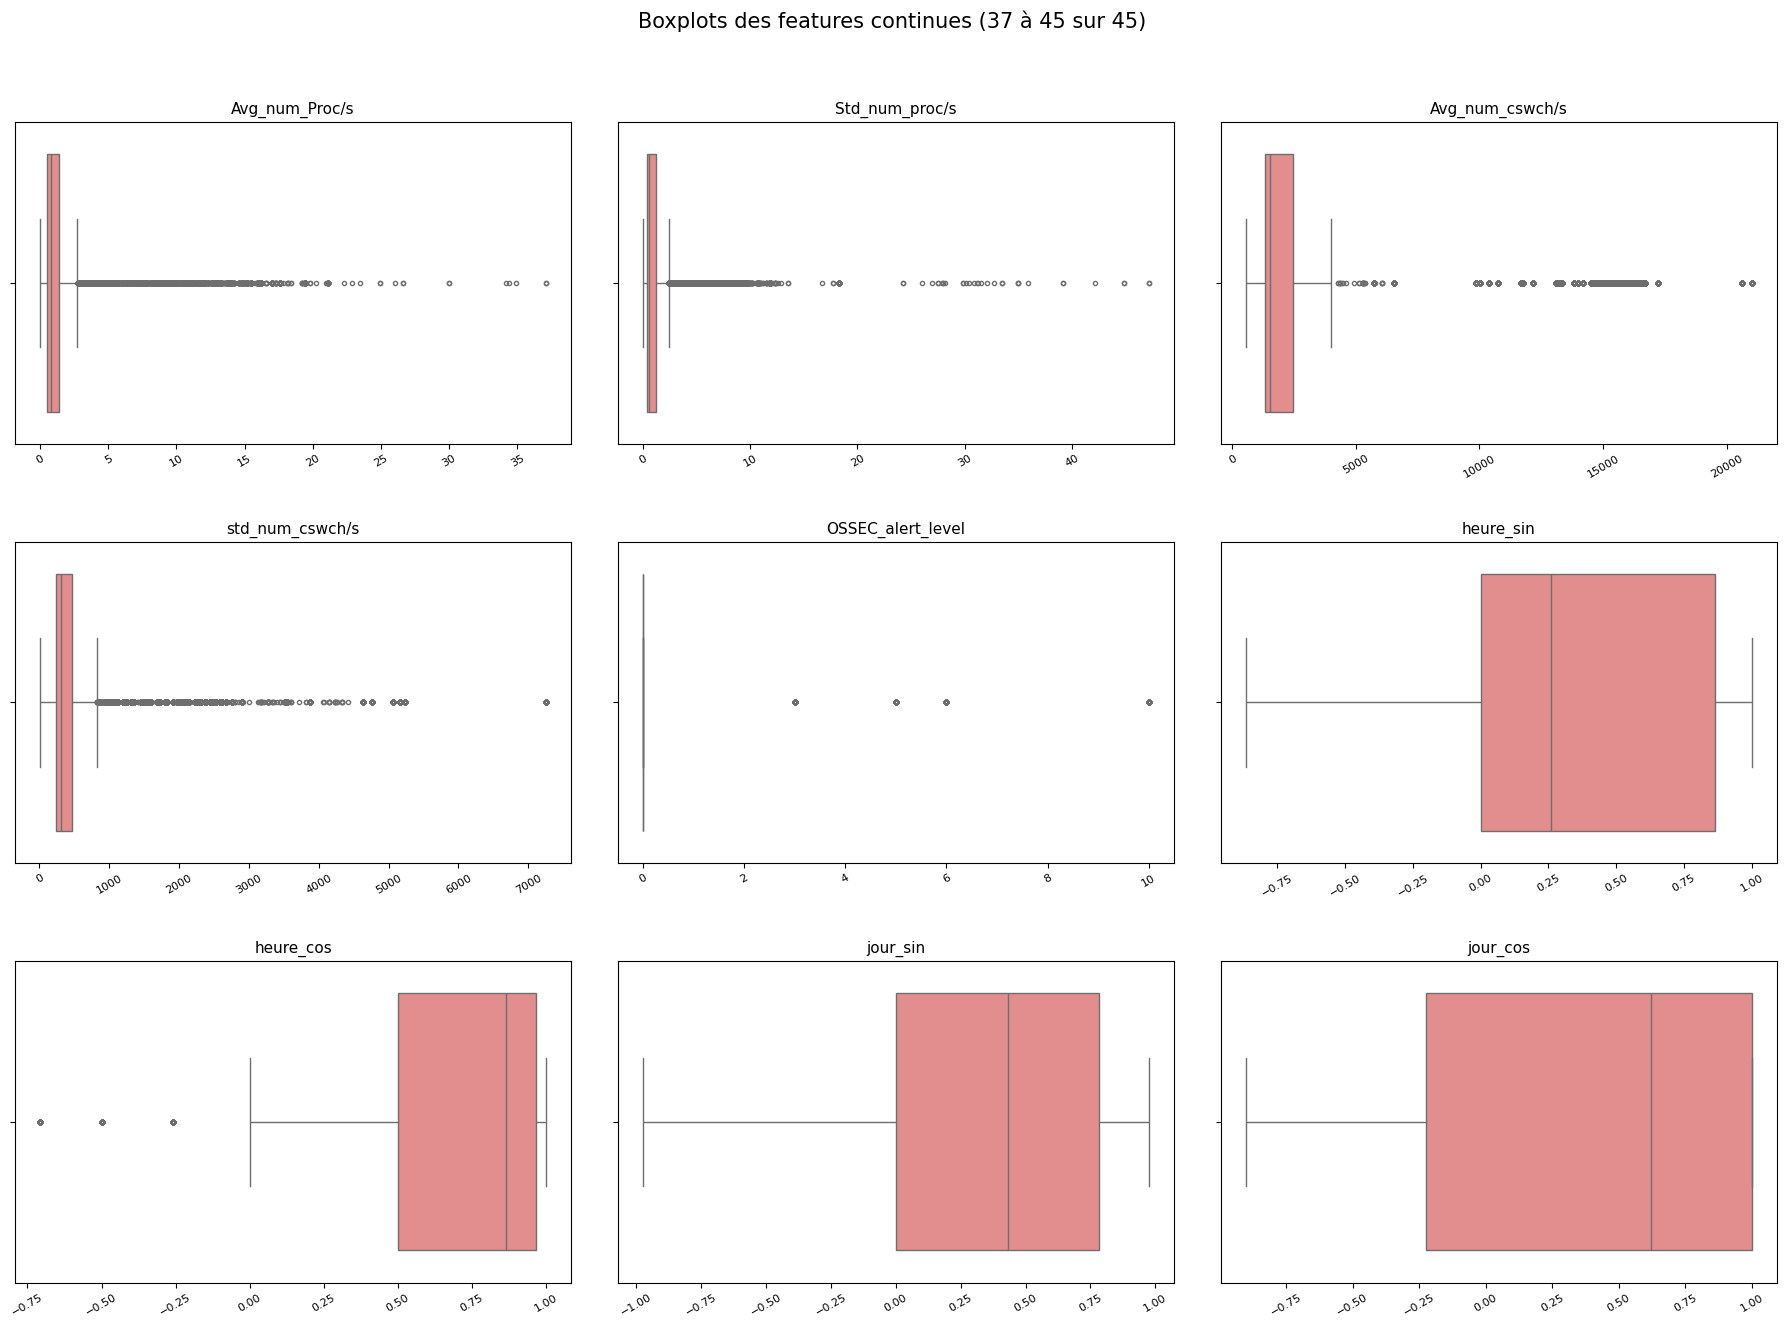

                   Nb valeurs extrêmes  % des lignes
Avg_num_cswch/s                   8736          17.5
Std_num_proc/s                    8687          17.4
Avg_system_time                   8668          17.3
Avg_user_time                     8559          17.1
std_num_cswch/s                   8536          17.1
total_bytes                       6921          13.8
Avg_num_Proc/s                    6529          13.1
Des_ip_bytes                      6325          12.6
Duration                          6147          12.3
Des_bytes                         6085          12.2
total_packet                      5847          11.7
Scr_ip_bytes                      5634          11.3
Des_pkts                          5584          11.2
Scr_pkts                          5539          11.1
byte_rate                         5448          10.9
paket_rate                        5225          10.4
Avg_iowait_time                   5023          10.0
Std_ldavg_1                       4956        

In [20]:
# Boxplot de chaque feature continue : les points au-delà des moustaches sont des valeurs extrêmes
def tracer_box(ax, c):
    sns.boxplot(x=X[c].dropna(), ax=ax, color="lightcoral", fliersize=3)
    ax.set_title(c, fontsize=11)
    ax.set_xlabel("")

grille(cont, tracer_box, "Boxplots des features continues")

# Règle IQR : une valeur est extrême si elle est hors de [Q1 - 1.5*IQR ; Q3 + 1.5*IQR]
Q1 = X[cont].quantile(0.25)
Q3 = X[cont].quantile(0.75)
IQR = Q3 - Q1
bas = Q1 - 1.5 * IQR
haut = Q3 + 1.5 * IQR

nb_extremes = ((X[cont] < bas) | (X[cont] > haut)).sum()

tab_out = pd.DataFrame({
    "Nb valeurs extrêmes": nb_extremes,
    "% des lignes": (nb_extremes / len(X) * 100).round(1),
}).sort_values("Nb valeurs extrêmes", ascending=False)

print(tab_out[tab_out["Nb valeurs extrêmes"] > 0])

In [21]:
# La cible est class3. class1 et class2 sont retirées de X : elles sont liées à class3
# et donneraient la réponse au modèle (fuite de données).
X = data_small.drop(columns=["class1", "class2", "class3"])
y = data_small["class3"]

print("X :", X.shape, "| y :", y.shape)
print("Colonnes non numériques :", X.select_dtypes(exclude="number").columns.tolist())  # Protocol et Service

X : (50000, 61) | y : (50000,)
Colonnes non numériques : ['Protocol', 'Service']


In [22]:
# Chaque classe doit avoir au moins 2 lignes pour que stratify fonctionne
stratif = y if y.value_counts().min() >= 2 else None
if stratif is None:
    print("ATTENTION : une classe a moins de 2 lignes, séparation non stratifiée.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratif
)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (40000, 61) | Test : (10000, 61)


In [23]:
# Indicateurs de valeurs manquantes (très recommandé) : le fait qu'une valeur manque est une information.
# J'en crée UN PAR GROUPE (3) et non un par colonne (15) : les colonnes d'un même groupe manquent
# exactement sur les mêmes lignes, donc 15 indicateurs seraient identiques (multicolinéarité).
# Ils sont calculés ligne par ligne : pas de fuite de données. Ils doivent être créés AVANT l'imputation.
groupes = {"octets": grp_A, "paquets": grp_B, "duration": grp_C}

for nom, cols_g in groupes.items():
    X_train[f"{nom}_was_missing"] = X_train[cols_g].isnull().any(axis=1).astype(int)
    X_test[f"{nom}_was_missing"] = X_test[cols_g].isnull().any(axis=1).astype(int)

print("Indicateurs créés :", [c for c in X_train.columns if "was_missing" in c])

Indicateurs créés : ['octets_was_missing', 'paquets_was_missing', 'duration_was_missing']


In [24]:
cat_features = ["Protocol", "Service"]
num_features = [c for c in X_train.columns if c not in cat_features]

print("Numériques :", len(num_features), "| Catégorielles :", len(cat_features))
print("Manquants dans X_train avant imputation :", X_train.isnull().sum().sum())

Numériques : 62 | Catégorielles : 2
Manquants dans X_train avant imputation : 133082


In [25]:
import time
from joblib import Parallel, delayed

X_train_knn = X_train.copy()
X_test_knn = X_test.copy()

# 1) Mise à l'échelle UNIQUEMENT pour calculer les distances (fit sur Train)
scaler_knn = RobustScaler()
tr_scaled = scaler_knn.fit_transform(X_train[num_features])
te_scaled = scaler_knn.transform(X_test[num_features])

# 2) L'imputer apprend sur un échantillon de Train (les voisins sont cherchés dedans)
N_FIT = 5000                       # baisse à 2000 si c'est encore trop lent
rng = np.random.RandomState(42)
idx = rng.choice(len(tr_scaled), size=min(N_FIT, len(tr_scaled)), replace=False)

t0 = time.time()
knn_imputer = KNNImputer(n_neighbors=5)
knn_imputer.fit(tr_scaled[idx])
print(f"Fit terminé en {time.time() - t0:.1f} s")

# 3) Imputation par morceaux, en parallèle
def imputer_morceau(M):
    return knn_imputer.transform(M)

def imputer_parallele(M, taille=2000):
    morceaux = [M[i:i + taille] for i in range(0, len(M), taille)]
    resultats = Parallel(n_jobs=-1, verbose=5)(delayed(imputer_morceau)(m) for m in morceaux)
    return np.vstack(resultats)

t0 = time.time()
tr_imp = imputer_parallele(tr_scaled)
print(f"Train imputé en {time.time() - t0:.1f} s")

t0 = time.time()
te_imp = imputer_parallele(te_scaled)
print(f"Test imputé en {time.time() - t0:.1f} s")

# 4) Retour à l'échelle d'origine
X_train_knn[num_features] = scaler_knn.inverse_transform(tr_imp)
X_test_knn[num_features] = scaler_knn.inverse_transform(te_imp)

# 5) Catégories : valeur la plus fréquente
cat_imputer_knn = SimpleImputer(strategy="most_frequent")
X_train_knn[cat_features] = cat_imputer_knn.fit_transform(X_train[cat_features])
X_test_knn[cat_features] = cat_imputer_knn.transform(X_test[cat_features])

print("\nImputation KNN terminée")
print("Manquants restants train :", X_train_knn.isnull().sum().sum())
print("Manquants restants test  :", X_test_knn.isnull().sum().sum())

Fit terminé en 0.0 s


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   12.7s
[Parallel(n_jobs=-1)]: Done  18 out of  20 | elapsed:   18.7s remaining:    2.0s
[Parallel(n_jobs=-1)]: Done  20 out of  20 | elapsed:   18.8s finished


Train imputé en 19.1 s


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:    2.2s remaining:    3.3s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    3.8s finished


Test imputé en 4.0 s

Imputation KNN terminée
Manquants restants train : 0
Manquants restants test  : 0


In [26]:
# Imputation numérique : médiane (robuste aux valeurs extrêmes).
# fit sur Train uniquement, puis transform sur Train et Test.
X_train_med = X_train.copy()
X_test_med = X_test.copy()

num_imputer = SimpleImputer(strategy="median")
X_train_med[num_features] = num_imputer.fit_transform(X_train_med[num_features])
X_test_med[num_features] = num_imputer.transform(X_test_med[num_features])

# Imputation catégorielle : valeur la plus fréquente (mode)
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_med[cat_features] = cat_imputer.fit_transform(X_train_med[cat_features])
X_test_med[cat_features] = cat_imputer.transform(X_test_med[cat_features])

print("Imputation médiane terminée")
print("Manquants restants train :", X_train_med.isnull().sum().sum())
print("Manquants restants test  :", X_test_med.isnull().sum().sum())

Imputation médiane terminée
Manquants restants train : 0
Manquants restants test  : 0


In [27]:
from sklearn.preprocessing import PowerTransformer

cycliques = ["heure_sin", "heure_cos", "jour_sin", "jour_cos"]

def sym_et_ecretage(Xtr, Xte, nom):
    """Yeo-Johnson puis écrêtage 1 %-99 %, tout appris sur Train et appliqué tel quel à Test.
    Xtr et Xte doivent déjà être imputés (aucun NaN)."""
    assert Xtr.isnull().sum().sum() == 0, "Xtr contient encore des NaN : imputer d'abord"
    assert Xte.isnull().sum().sum() == 0, "Xte contient encore des NaN : imputer d'abord"

    # 1) Colonnes asymétriques (|skew| >= 1), calculées sur Train imputé
    skew_tr = Xtr[num_features].skew()
    cols_asym = [c for c in num_features
                 if abs(skew_tr[c]) >= 1
                 and Xtr[c].nunique() > 2
                 and c not in cycliques]

    # 2) Yeo-Johnson (exposant appris sur Train)
    Xtr_sym, Xte_sym = Xtr.copy(), Xte.copy()
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    Xtr_sym[cols_asym] = pt.fit_transform(Xtr[cols_asym])
    Xte_sym[cols_asym] = pt.transform(Xte[cols_asym])

    # 3) Écrêtage (winsorisation) : percentiles 1 % et 99 % de Train
    cont_out = [c for c in num_features
                if Xtr_sym[c].nunique() > 2 and c not in cycliques]
    bas_w = Xtr_sym[cont_out].quantile(0.01)
    haut_w = Xtr_sym[cont_out].quantile(0.99)

    Xtr_w, Xte_w = Xtr_sym.copy(), Xte_sym.copy()
    Xtr_w[cont_out] = Xtr_sym[cont_out].clip(lower=bas_w, upper=haut_w, axis=1)
    Xte_w[cont_out] = Xte_sym[cont_out].clip(lower=bas_w, upper=haut_w, axis=1)

    # 4) Contrôles
    print(f"--- {nom} ---")
    print("Colonnes corrigées (Yeo-Johnson) :", len(cols_asym))
    print("Encore asymétriques après :", (Xtr_sym[cols_asym].skew().abs() >= 1).sum())
    print("NaN restants (Train / Test) :", Xtr_w.isnull().sum().sum(), "/", Xte_w.isnull().sum().sum())
    print("Lignes conservées (Train / Test) :", len(Xtr_w), "/", len(Xte_w), "\n")

    return Xtr_sym, Xte_sym, Xtr_w, Xte_w, cols_asym, cont_out

# ---------- Version MÉDIANE ----------
X_train_med_sym, X_test_med_sym, X_train_med_w, X_test_med_w, cols_asym_med, cont_out_med = \
    sym_et_ecretage(X_train_med, X_test_med, "Médiane")

# ---------- Version KNN ----------
X_train_knn_sym, X_test_knn_sym, X_train_knn_w, X_test_knn_w, cols_asym_knn, cont_out_knn = \
    sym_et_ecretage(X_train_knn, X_test_knn, "KNN")

--- Médiane ---
Colonnes corrigées (Yeo-Johnson) : 36
Encore asymétriques après : 2
NaN restants (Train / Test) : 0 / 0
Lignes conservées (Train / Test) : 40000 / 10000 

--- KNN ---
Colonnes corrigées (Yeo-Johnson) : 34
Encore asymétriques après : 2
NaN restants (Train / Test) : 0 / 0
Lignes conservées (Train / Test) : 40000 / 10000 



In [28]:
from sklearn.preprocessing import PowerTransformer

cycliques = ["heure_sin", "heure_cos", "jour_sin", "jour_cos"]

def sym_et_ecretage(Xtr, Xte, nom):
    """Yeo-Johnson puis écrêtage 1 %-99 %, tout appris sur Train et appliqué tel quel à Test.
    Xtr et Xte doivent déjà être imputés (aucun NaN)."""
    assert Xtr.isnull().sum().sum() == 0, "Xtr contient encore des NaN : imputer d'abord"
    assert Xte.isnull().sum().sum() == 0, "Xte contient encore des NaN : imputer d'abord"

    # 1) Colonnes asymétriques (|skew| >= 1), calculées sur Train imputé
    skew_tr = Xtr[num_features].skew()
    cols_asym = [c for c in num_features
                 if abs(skew_tr[c]) >= 1
                 and Xtr[c].nunique() > 2
                 and c not in cycliques]

    # 2) Yeo-Johnson (exposant appris sur Train)
    Xtr_sym, Xte_sym = Xtr.copy(), Xte.copy()
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    Xtr_sym[cols_asym] = pt.fit_transform(Xtr[cols_asym])
    Xte_sym[cols_asym] = pt.transform(Xte[cols_asym])

    # 3) Écrêtage (winsorisation) : percentiles 1 % et 99 % de Train
    cont_out = [c for c in num_features
                if Xtr_sym[c].nunique() > 2 and c not in cycliques]
    bas_w = Xtr_sym[cont_out].quantile(0.01)
    haut_w = Xtr_sym[cont_out].quantile(0.99)

    Xtr_w, Xte_w = Xtr_sym.copy(), Xte_sym.copy()
    Xtr_w[cont_out] = Xtr_sym[cont_out].clip(lower=bas_w, upper=haut_w, axis=1)
    Xte_w[cont_out] = Xte_sym[cont_out].clip(lower=bas_w, upper=haut_w, axis=1)

    # 4) Contrôles
    print(f"--- {nom} ---")
    print("Colonnes corrigées (Yeo-Johnson) :", len(cols_asym))
    print("Encore asymétriques après :", (Xtr_sym[cols_asym].skew().abs() >= 1).sum())
    print("NaN restants (Train / Test) :", Xtr_w.isnull().sum().sum(), "/", Xte_w.isnull().sum().sum())
    print("Lignes conservées (Train / Test) :", len(Xtr_w), "/", len(Xte_w), "\n")

    return Xtr_sym, Xte_sym, Xtr_w, Xte_w, cols_asym, cont_out

# ---------- Version MÉDIANE ----------
X_train_med_sym, X_test_med_sym, X_train_med_w, X_test_med_w, cols_asym_med, cont_out_med = \
    sym_et_ecretage(X_train_med, X_test_med, "Médiane")

# ---------- Version KNN ----------
X_train_knn_sym, X_test_knn_sym, X_train_knn_w, X_test_knn_w, cols_asym_knn, cont_out_knn = \
    sym_et_ecretage(X_train_knn, X_test_knn, "KNN")

--- Médiane ---
Colonnes corrigées (Yeo-Johnson) : 36
Encore asymétriques après : 2
NaN restants (Train / Test) : 0 / 0
Lignes conservées (Train / Test) : 40000 / 10000 

--- KNN ---
Colonnes corrigées (Yeo-Johnson) : 34
Encore asymétriques après : 2
NaN restants (Train / Test) : 0 / 0
Lignes conservées (Train / Test) : 40000 / 10000 



In [29]:
# Analyse faite sur la version médiane, après Yeo-Johnson
Xs = X_train_med_sym
Q1 = Xs[cont_out_med].quantile(0.25)
Q3 = Xs[cont_out_med].quantile(0.75)
IQR = Q3 - Q1
bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR            # bornes apprises sur Train

masque = (Xs[cont_out_med] < bas) | (Xs[cont_out_med] > haut)   # True = valeur extrême
nb = masque.sum()
tab = pd.DataFrame({"Nb extrêmes": nb, "% lignes": (nb / len(Xs) * 100).round(1)})
print(tab[tab["Nb extrêmes"] > 0].sort_values("Nb extrêmes", ascending=False))

# Les valeurs extrêmes sont-elles des attaques ?
y_tr = (y_train == "Attack").astype(int)
lignes = []
for c in cont_out_med:
    m = masque[c]
    if m.sum() > 0:
        lignes.append({"feature": c,
                       "% attaque si extrême": round(y_tr[m].mean() * 100, 1),
                       "% attaque sinon": round(y_tr[~m].mean() * 100, 1)})
print("\n(rappel : % d'attaques sur Train =", round(y_tr.mean() * 100, 1), ")")
if lignes:
    info = pd.DataFrame(lignes).set_index("feature")
    info["écart"] = (info["% attaque si extrême"] - info["% attaque sinon"]).round(1)
    print(info.sort_values("écart", key=abs, ascending=False))
else:
    print("Aucune valeur extrême détectée.")

print("\nÉcrêtage déjà fait dans la cellule 30 : X_train_med_w / X_train_knn_w")

                   Nb extrêmes  % lignes
Scr_bytes_ratio          12721      31.8
Des_bytes_ratio          12721      31.8
Des_bytes                12025      30.1
Des_ip_bytes             10799      27.0
Scr_bytes                 4825      12.1
Std_kbmemused             3424       8.6
Std_nice_time             2211       5.5
OSSEC_alert_level         2154       5.4
Std_ideal_time            2071       5.2
std_num_cswch/s           1703       4.3
Avg_num_Proc/s            1594       4.0
Avg_nice_time             1467       3.7
Avg_kbmemused             1360       3.4
Scr_packts_ratio          1051       2.6
Std_user_time             1043       2.6
Des_pkts_ratio             632       1.6
Avg_user_time              598       1.5
Std_tps                    593       1.5
Std_wtps                   384       1.0
Std_system_time            285       0.7
byte_rate                  245       0.6
Avg_tps                    137       0.3
Std_num_proc/s              66       0.2
Scr_ip_bytes    

In [30]:
# Scaling + One-Hot.
# Mêmes étapes pour Médiane et KNN : seule l'imputation les différencie.
# Tout est appris (fit) sur Train, puis appliqué (transform) à Test.

cycliques = ["heure_sin", "heure_cos", "jour_sin", "jour_cos"]

def scaling_et_onehot(Xtr, Xte, nom):
    # Colonnes à mettre à l'échelle : les continues (on laisse telles quelles
    # les binaires 0/1 et les cycliques sin/cos, qui ont déjà une échelle correcte)
    cols_scale = [c for c in num_features
                  if Xtr[c].nunique() > 2 and c not in cycliques]
    cols_pass = [c for c in num_features if c not in cols_scale]   # binaires + cycliques

    prep = ColumnTransformer(
        transformers=[
            ("scale", RobustScaler(), cols_scale),
            ("pass", "passthrough", cols_pass),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
        ],
        verbose_feature_names_out=False,
    )

    # fit sur Train uniquement
    Xtr_arr = prep.fit_transform(Xtr)
    Xte_arr = prep.transform(Xte)

    noms_cols = prep.get_feature_names_out()
    Xtr_final = pd.DataFrame(Xtr_arr, columns=noms_cols, index=Xtr.index)
    Xte_final = pd.DataFrame(Xte_arr, columns=noms_cols, index=Xte.index)

    # Contrôles
    print(f"--- {nom} ---")
    print("Colonnes mises à l'échelle :", len(cols_scale))
    print("Colonnes laissées telles quelles :", len(cols_pass))
    print("Colonnes One-Hot créées :", len([c for c in noms_cols
          if c.startswith(tuple(f"{k}_" for k in cat_features))]))
    print("Shape finale Train / Test :", Xtr_final.shape, "/", Xte_final.shape)
    print("NaN restants Train / Test :", Xtr_final.isnull().sum().sum(), "/", Xte_final.isnull().sum().sum())
    print("Colonnes non numériques restantes :",
          Xtr_final.select_dtypes(exclude="number").columns.tolist(), "\n")

    return Xtr_final, Xte_final, prep

# ---------- Version MÉDIANE ----------
X_train_med_final, X_test_med_final, prep_med = scaling_et_onehot(
    X_train_med_w, X_test_med_w, "Médiane")

# ---------- Version KNN ----------
X_train_knn_final, X_test_knn_final, prep_knn = scaling_et_onehot(
    X_train_knn_w, X_test_knn_w, "KNN")

# Vérification : les deux versions doivent avoir exactement les mêmes colonnes
print("Mêmes colonnes dans les deux versions :",
      list(X_train_med_final.columns) == list(X_train_knn_final.columns))

--- Médiane ---
Colonnes mises à l'échelle : 40
Colonnes laissées telles quelles : 22
Colonnes One-Hot créées : 20
Shape finale Train / Test : (40000, 82) / (10000, 82)
NaN restants Train / Test : 0 / 0
Colonnes non numériques restantes : [] 

--- KNN ---
Colonnes mises à l'échelle : 40
Colonnes laissées telles quelles : 22
Colonnes One-Hot créées : 20
Shape finale Train / Test : (40000, 82) / (10000, 82)
NaN restants Train / Test : 0 / 0
Colonnes non numériques restantes : [] 

Mêmes colonnes dans les deux versions : True


In [31]:
import time
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

cycliques = ["heure_sin", "heure_cos", "jour_sin", "jour_cos"]
fe_cols = cycliques + [c for c in X_train.columns if c.endswith("_was_missing")]

# ---------- 1) Construire les 8 cas ----------
sources = {
    ("Médiane", "Baseline"):  (X_train_med,   X_test_med),
    ("Médiane", "Prétraité"): (X_train_med_w, X_test_med_w),
    ("KNN",     "Baseline"):  (X_train_knn,   X_test_knn),
    ("KNN",     "Prétraité"): (X_train_knn_w, X_test_knn_w),
}
cas = {}
for (imp, prep_nom), (Xtr, Xte) in sources.items():
    for fe in [False, True]:
        cols = list(Xtr.columns) if fe else [c for c in Xtr.columns if c not in fe_cols]
        nom = f"{imp} | {prep_nom} | {'avec FE' if fe else 'sans FE'}"
        cas[nom] = (Xtr[cols], Xte[cols])
print(len(cas), "cas construits")

# ---------- 2) Pipeline : scaling + One-Hot + régression logistique ----------
def faire_pipeline(Xtr, C=1.0, class_weight=None):
    cat = [c for c in cat_features if c in Xtr.columns]
    num = [c for c in Xtr.columns if c not in cat]
    cols_scale = [c for c in num if Xtr[c].nunique() > 2 and c not in cycliques]
    cols_pass = [c for c in num if c not in cols_scale]       # binaires + cycliques
    prep = ColumnTransformer([
        ("scale", RobustScaler(), cols_scale),
        ("pass", "passthrough", cols_pass),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(C=C, class_weight=class_weight,
                                   max_iter=500, tol=1e-3, random_state=42)),
    ])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# ---------- 3) Cible en 0/1 et fonction de métriques ----------
# Attack = 1 (classe positive), Normal = 0
y_train_b = (y_train == "Attack").astype(int)
y_test_b = (y_test == "Attack").astype(int)

def metriques(y_vrai, y_pred, score):
    return {
        "Accuracy":  accuracy_score(y_vrai, y_pred),
        "Precision": precision_score(y_vrai, y_pred),
        "Recall":    recall_score(y_vrai, y_pred),
        "F1":        f1_score(y_vrai, y_pred),
        "AUC-ROC":   roc_auc_score(y_vrai, score),
    }

scoring_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# ---------- 4) Évaluation de chaque cas ----------
lignes_cv, lignes_test, lignes_over = [], [], []
t_total = time.time()

for i, (nom, (Xtr, Xte)) in enumerate(cas.items(), start=1):
    t0 = time.time()
    pipe = faire_pipeline(Xtr)

    # Validation croisée sur Train (données jamais vues dans chaque pli)
    r = cross_validate(pipe, Xtr, y_train_b, cv=cv, n_jobs=-1, scoring=scoring_cv)
    lignes_cv.append({"Cas": nom,
                      "Accuracy":  r["test_accuracy"].mean(),
                      "Precision": r["test_precision"].mean(),
                      "Recall":    r["test_recall"].mean(),
                      "F1":        r["test_f1"].mean(),
                      "AUC-ROC":   r["test_roc_auc"].mean()})

    # Entraînement sur tout Train, puis métriques sur Train et Test
    pipe.fit(Xtr, y_train_b)
    m_tr = metriques(y_train_b, pipe.predict(Xtr), pipe.predict_proba(Xtr)[:, 1])
    m_te = metriques(y_test_b, pipe.predict(Xte), pipe.predict_proba(Xte)[:, 1])

    lignes_test.append({"Cas": nom, **m_te})
    lignes_over.append({"Cas": nom, **{k: m_tr[k] - m_te[k] for k in m_tr}})
    print(f"[{i}/{len(cas)}] {nom:40s} terminé en {time.time() - t0:.0f} s")

print(f"\nTemps total : {(time.time() - t_total) / 60:.1f} min")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

tab_cv = pd.DataFrame(lignes_cv).set_index("Cas").sort_values("F1", ascending=False)
tab_test = pd.DataFrame(lignes_test).set_index("Cas").loc[tab_cv.index]
tab_over = pd.DataFrame(lignes_over).set_index("Cas").loc[tab_cv.index]

print("\n=== 1) VALIDATION CROISÉE sur TRAIN (sert à choisir) ===")
print(tab_cv.round(4))
print("\n=== 2) TEST (sert à confirmer) ===")
print(tab_test.round(4))
print("\n=== 3) SURAPPRENTISSAGE : écart Train - Test (proche de 0 = OK) ===")
print(tab_over.round(4))

8 cas construits
[1/8] Médiane | Baseline | sans FE             terminé en 31 s
[2/8] Médiane | Baseline | avec FE             terminé en 22 s
[3/8] Médiane | Prétraité | sans FE            terminé en 3 s
[4/8] Médiane | Prétraité | avec FE            terminé en 3 s
[5/8] KNN | Baseline | sans FE                 terminé en 22 s
[6/8] KNN | Baseline | avec FE                 terminé en 19 s
[7/8] KNN | Prétraité | sans FE                terminé en 2 s
[8/8] KNN | Prétraité | avec FE                terminé en 2 s

Temps total : 1.7 min

=== 1) VALIDATION CROISÉE sur TRAIN (sert à choisir) ===
                               Accuracy  Precision  Recall      F1  AUC-ROC
Cas                                                                        
Médiane | Prétraité | avec FE    0.9763     0.9878  0.9632  0.9754   0.9938
Médiane | Prétraité | sans FE    0.9758     0.9865  0.9636  0.9749   0.9925
KNN | Prétraité | sans FE        0.9757     0.9851  0.9646  0.9747   0.9924
KNN | Prétraité | avec

In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

nom_cas = "Médiane | Prétraité | sans FE"
Xtr, Xte = cas[nom_cas]
print("Cas retenu :", nom_cas)

pipe = faire_pipeline(Xtr)
grille = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"],
}
gs = GridSearchCV(pipe, grille, cv=cv, scoring="f1",      # F1 de la classe Attack
                  n_jobs=-1, return_train_score=True, verbose=1)
gs.fit(Xtr, y_train_b)

print("\nMeilleurs paramètres :", gs.best_params_)
res = pd.DataFrame(gs.cv_results_)[["param_clf__C", "param_clf__class_weight",
                                    "mean_train_score", "mean_test_score"]]
res["écart"] = res["mean_train_score"] - res["mean_test_score"]
print(res.sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

# Évaluation finale, une seule fois
mf = gs.best_estimator_
m_tr = metriques(y_train_b, mf.predict(Xtr), mf.predict_proba(Xtr)[:, 1])
m_te = metriques(y_test_b, mf.predict(Xte), mf.predict_proba(Xte)[:, 1])
final = pd.DataFrame({"Train": m_tr, "Test": m_te}).round(4)
final["Écart"] = (final["Train"] - final["Test"]).round(4)
print("\n=== Modèle final ===")
print(final)

print("\n", classification_report(y_test_b, mf.predict(Xte),
                                  target_names=["Normal", "Attack"], digits=4))
print("Matrice de confusion (Test) :  lignes = vrai, colonnes = prédit")
print(pd.DataFrame(confusion_matrix(y_test_b, mf.predict(Xte)),
                   index=["Vrai Normal", "Vrai Attack"],
                   columns=["Prédit Normal", "Prédit Attack"]))

Cas retenu : Médiane | Prétraité | sans FE
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Meilleurs paramètres : {'clf__C': 100, 'clf__class_weight': None}
 param_clf__C param_clf__class_weight  mean_train_score  mean_test_score   écart
       100.00                     NaN            0.9776           0.9771  0.0005
        10.00                balanced            0.9769           0.9767  0.0002
        10.00                     NaN            0.9770           0.9766  0.0004
       100.00                balanced            0.9768           0.9763  0.0005
         1.00                balanced            0.9754           0.9751  0.0003
         1.00                     NaN            0.9753           0.9749  0.0004
         0.10                     NaN            0.9711           0.9711 -0.0000
         0.10                balanced            0.9710           0.9710  0.0000
         0.01                balanced            0.9590           0.9593 -0.0003
         0.01      

In [33]:
# ==========================================
# 1. SÉLECTION DE 10000 NOUVELLES LIGNES + SAUVEGARDE
# ==========================================
import os

# 10000 lignes tirées dans les données jamais utilisées (ni Train, ni Test)
data_val, _ = train_test_split(
    data_unused,
    train_size=10000,
    stratify=data_unused["class3"],
    random_state=2026
)

# Sécurité : toutes les lignes viennent bien de data_unused (aucune ligne commune avec les 50000)
assert data_val.index.isin(data_unused.index).all(), "Erreur : lignes hors data_unused"

data_val = data_val.copy().reset_index(drop=True)

print("Validation indépendante :", data_val.shape)
print("\nRépartition des classes :")
print(data_val["class3"].value_counts())
print("\nPourcentage des classes :")
print((data_val["class3"].value_counts(normalize=True) * 100).round(2))

# ------------------------------------------
#2.  Sauvegarde dans data/raw (données brutes, avant préparation)
# ------------------------------------------
DOSSIER_RAW = "C:/Users/Administrateur/mlops-ids-attaque/data/raw"
os.makedirs(DOSSIER_RAW, exist_ok=True)

chemin_val = f"{DOSSIER_RAW}/data_val_10000.csv"
data_val.to_csv(chemin_val, index=False)

# Contrôle : on relit le fichier pour vérifier qu'il est complet
controle = pd.read_csv(chemin_val)
print(f"\nFichier sauvegardé : {chemin_val}")
print("Lignes / colonnes relues :", controle.shape)
print("Taille du fichier : %.1f Mo" % (os.path.getsize(chemin_val) / 1024**2))

Validation indépendante : (10000, 66)

Répartition des classes :
class3
Normal    5136
Attack    4864
Name: count, dtype: int64

Pourcentage des classes :
class3
Normal    51.36
Attack    48.64
Name: proportion, dtype: float64

Fichier sauvegardé : C:/Users/Administrateur/mlops-ids-attaque/data/raw/data_val_10000.csv
Lignes / colonnes relues : (10000, 66)
Taille du fichier : 4.2 Mo


In [34]:
# ==========================================
# 3. PRÉPARATION DES DONNÉES
# ==========================================

# 1. Conversion des dates
data_val["Date"] = pd.to_datetime(
    data_val["Date"],
    dayfirst=True,
    errors="coerce"
)

data_val["Timestamp"] = pd.to_datetime(
    pd.to_numeric(data_val["Timestamp"], errors="coerce"),
    unit="s",
    errors="coerce"
)

# 2. Feature Engineering temporel
heure = data_val["Timestamp"].dt.hour
jour = data_val["Timestamp"].dt.day_of_week

data_val["heure_sin"] = np.sin(2 * np.pi * heure / 24)
data_val["heure_cos"] = np.cos(2 * np.pi * heure / 24)

data_val["jour_sin"] = np.sin(2 * np.pi * jour / 7)
data_val["jour_cos"] = np.cos(2 * np.pi * jour / 7)

# 3. Suppression des colonnes identifiantes
data_val = data_val.drop(
    columns=[
        "Scr_IP", "Des_IP",
        "Scr_port", "Des_port",
        "Date", "Timestamp"
    ],
    errors="ignore"
)

# 4. Conversion de anomaly_alert
data_val["anomaly_alert"] = (
    data_val["anomaly_alert"]
    .astype(str)
    .str.upper()
    .map({
        "TRUE": 1,
        "FALSE": 0,
        "1": 1,
        "0": 0
    })
)

# 5. Conversion des booléens en 0/1
bool_cols = data_val.select_dtypes(include="bool").columns

data_val[bool_cols] = data_val[bool_cols].astype(int)

print("Préparation terminée :", data_val.shape)

Préparation terminée : (10000, 64)


In [35]:
# ==========================================
# 4. SÉPARATION X / y
# ==========================================

X_val = data_val.drop(
    columns=["class1", "class2", "class3"]
)

y_val = data_val["class3"].copy()

# 1. Création des indicateurs de valeurs manquantes
for nom, cols_g in groupes.items():

    X_val[f"{nom}_was_missing"] = (
        X_val[cols_g]
        .isnull()
        .any(axis=1)
        .astype(int)
    )

# 2. Respecter exactement les colonnes de Train
X_val = X_val.reindex(columns=X_train.columns)

print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("Valeurs manquantes :", X_val.isnull().sum().sum())

X_val : (10000, 64)
y_val : (10000,)
Valeurs manquantes : 32747


In [36]:
# ==========================================
# 5. IMPUTATION PAR LA MÉDIANE
# ==========================================

X_val_med = X_val.copy()

# Imputation numérique avec la médiane de Train
X_val_med[num_features] = num_imputer.transform(
    X_val_med[num_features]
)

# Imputation catégorielle avec le mode de Train
X_val_med[cat_features] = cat_imputer.transform(
    X_val_med[cat_features]
)

print("Valeurs manquantes avant :", X_val.isnull().sum().sum())

print("Valeurs manquantes après :",
      X_val_med.isnull().sum().sum())

Valeurs manquantes avant : 32747
Valeurs manquantes après : 0


In [37]:
# ==========================================
# 6. YEO-JOHNSON ET ÉCRÊTAGE
# ==========================================

from sklearn.preprocessing import PowerTransformer

# 1. Yeo-Johnson
# Apprendre les paramètres uniquement sur Train

pt_val = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

pt_val.fit(X_train_med[cols_asym_med])

# Appliquer aux nouvelles données
X_val_sym = X_val_med.copy()

X_val_sym[cols_asym_med] = pt_val.transform(
    X_val_med[cols_asym_med]
)

# 2. Bornes d'écrêtage calculées sur Train
bas_w = X_train_med_sym[cont_out_med].quantile(0.01)

haut_w = X_train_med_sym[cont_out_med].quantile(0.99)

# 3. Appliquer l'écrêtage aux nouvelles données
X_val_w = X_val_sym.copy()

X_val_w[cont_out_med] = X_val_sym[cont_out_med].clip(
    lower=bas_w,
    upper=haut_w,
    axis=1
)

print("Yeo-Johnson terminé.")
print("Écrêtage terminé.")

print("NaN restants :", X_val_w.isnull().sum().sum())
print("Shape :", X_val_w.shape)

Yeo-Johnson terminé.
Écrêtage terminé.
NaN restants : 0
Shape : (10000, 64)


In [38]:
# ==========================================
# 7. ÉVALUATION INDÉPENDANTE
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# 1. Configuration retenue
nom_cas = "Médiane | Prétraité | sans FE"

Xtr, Xte = cas[nom_cas]

print("Configuration :", nom_cas)
print("Meilleurs paramètres :", mf.best_params_ if hasattr(mf, "best_params_") else gs.best_params_)

# 2. Sélection des mêmes variables que Train
X_val_final = X_val_w[Xtr.columns]

print("\nTrain :", Xtr.shape)
print("Validation :", X_val_final.shape)

# 3. Transformation de la cible
# Attack = 1 ; Normal = 0
y_val_b = (y_val == "Attack").astype(int)

# 4. Prédictions avec le modèle déjà entraîné
y_pred = mf.predict(X_val_final)

y_score = mf.predict_proba(X_val_final)[:, 1]

# 5. Calcul des métriques
print("\n========== VALIDATION SUR 10000 LIGNES ==========")

print("Accuracy  :", round(accuracy_score(y_val_b, y_pred), 4))

print("Precision :", round(precision_score(y_val_b, y_pred), 4))

print("Recall    :", round(recall_score(y_val_b, y_pred), 4))

print("F1-score  :", round(f1_score(y_val_b, y_pred), 4))

print("AUC-ROC   :", round(roc_auc_score(y_val_b, y_score), 4))


# 6. Rapport de classification
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_val_b,
    y_pred,
    target_names=["Normal", "Attack"],
    digits=4
))


# 7. Matrice de confusion
print("\n========== MATRICE DE CONFUSION ==========")

matrice = confusion_matrix(y_val_b, y_pred)

display(pd.DataFrame(
    matrice,
    index=["Vrai Normal", "Vrai Attack"],
    columns=["Prédit Normal", "Prédit Attack"]
))

Configuration : Médiane | Prétraité | sans FE
Meilleurs paramètres : {'clf__C': 100, 'clf__class_weight': None}

Train : (40000, 57)
Validation : (10000, 57)

========== VALIDATION SUR 10000 LIGNES ==========
Accuracy  : 0.9761
Precision : 0.9888
Recall    : 0.9618
F1-score  : 0.9751
AUC-ROC   : 0.9929

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Normal     0.9647    0.9897    0.9770      5136
      Attack     0.9888    0.9618    0.9751      4864

    accuracy                         0.9761     10000
   macro avg     0.9767    0.9757    0.9761     10000
weighted avg     0.9764    0.9761    0.9761     10000


========== MATRICE DE CONFUSION ==========


,Prédit Normal,Prédit Attack
Vrai Normal,5083,53
Vrai Attack,186,4678


In [39]:
# ==========================================
# 8. ANALYSE DES PRÉDICTIONS
# ==========================================

resultats = pd.DataFrame({

    "Classe réelle": y_val.values,

    "Classe prédite": np.where(
        y_pred == 1,
        "Attack",
        "Normal"
    ),

    "Probabilité Attack (%)": (
        y_score * 100
    ).round(2),

    "Correct": (
        y_val_b.to_numpy() == y_pred
    )

})

display(resultats)

# Résumé
nb_correct = resultats["Correct"].sum()

nb_incorrect = (~resultats["Correct"]).sum()

print("\n========== RÉSUMÉ ==========")

print("Nombre total :", len(resultats))

print("Prédictions correctes :", nb_correct)

print("Prédictions incorrectes :", nb_incorrect)

print("Taux de réussite :",
      round(nb_correct / len(resultats) * 100, 2), "%")

,Classe réelle,Classe prédite,Probabilité Attack (%),Correct
0,Attack,Attack,100.00,True
1,Attack,Attack,100.00,True
2,Normal,Normal,14.01,True
3,Attack,Attack,99.67,True
4,Attack,Attack,94.71,True
...,...,...,...,...
9995,Normal,Normal,2.58,True
9996,Normal,Normal,6.90,True
9997,Attack,Attack,98.26,True
9998,Attack,Attack,100.00,True



========== RÉSUMÉ ==========
Nombre total : 10000
Prédictions correctes : 9761
Prédictions incorrectes : 239
Taux de réussite : 97.61 %
